In [19]:
# Import required libraries
!pip install kds
!pip install xgboost

import kds
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, roc_auc_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Set display options for better readability
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

In [20]:
#import dataset and save it to customer
customer=pd.read_csv("datafile_full.csv")
customer.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19,var_20,var_21,var_22,var_23,var_24,var_25,var_26,var_27,var_28,var_29,var_30,var_31,var_32,var_33,var_34,var_35,var_36,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49,var_50,var_51,var_52,var_53,var_54,var_55,var_56,var_57,var_58,var_59,var_60,var_61,var_62,var_63,var_64,var_65,var_66,var_67,var_68,var_69,var_70,var_71,var_72,var_73,var_74,var_75,var_76,var_77,var_78,var_79,var_80,var_81,var_82,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_90,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100,var_101,var_102,var_103,var_104,var_105,var_106,var_107,var_108,var_109,var_110,var_111,var_112,var_113,var_114,var_115,var_116,var_117,var_118,var_119,var_120,var_121,var_122,var_123,var_124,var_125,var_126,var_127,var_128,var_129,var_130,var_131,var_132,var_133,var_134,var_135,var_136,var_137,var_138,var_139,var_140,var_141,var_142,var_143,var_144,var_145,var_146,var_147,var_148,var_149,var_150,var_151,var_152,var_153,var_154,var_155,var_156,var_157,var_158,var_159,var_160,var_161,var_162,var_163,var_164,var_165,var_166,var_167,var_168,var_169,var_170,var_171,var_172,var_173,var_174,var_175,var_176,var_177,var_178,var_179,var_180,var_181,var_182,var_183,var_184,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,125172.0,0,10.6216,0.1667,15.5182,10.1634,9.8419,-0.1156,7.4348,14.6948,-2.6715,7.6273,5.1050,-4.0113,14.3657,11.3376,7.0520,13.9277,10.6719,-5.8096,10.5765,0.5778,14.8409,0.7735,10.8010,2.6956,12.1779,13.8927,-3.7460,-3.6326,6.1669,0.3282,-7.2691,8.1598,4.6200,14.0259,11.8502,4.2248,7.1710,7.4430,5.5972,8.7985,3.0804,8.0540,10.7530,11.2322,12.2772,-40.9368,11.0163,-11.6099,39.6140,17.1918,13.4373,9.3009,-1.5859,5.7407,-1.2655,6.1793,20.0895,6.0746,0.2753,9.5349,16.6358,-11.7460,-1.6959,-0.9693,6.0779,-1.2174,5.9151,26.3157,5.0244,-3.8019,15.3821,0.6802,-2.6122,23.2965,22.0007,9.9715,13.6596,12.3873,4.1605,14.4118,4.2748,16.5846,-6.7645,2.6710,7.8049,22.5605,0.7140,2.1096,10.1921,1.0071,-6.1596,7.3113,6.8867,11.3828,9.6943,0.6122,13.4927,33.7480,1.6235,-1.1430,-10.1663,13.4993,22.4144,1.7327,11.1537,5.2462,4.8071,22.3990,14.2590,23.1477,3.8431,6.7428,3.8569,10.0244,1.8809,3.4100,3.3793,13.1888,-18.5847,5.5451,0.3824,11.3076,-1.0654,0.2773,0.8779,12.4115,12.3109,6.9240,0.3856,22.3957,10.6994,0.1996,9.2937,7.1135,-1.9853,-8.0729,25.3776,4.9800,-4.7898,14.8919,0.9508,14.1678,17.6415,9.1477,10.6999,6.0717,12.0532,-7.6234,3.7478,12.2441,15.4985,9.8282,5.2714,20.4594,8.1264,7.6986,14.2729,-11.5342,2.1366,12.4049,11.6347,5.8375,5.7337,8.9410,0.6580,16.4657,3.0601,-1.1128,0.2279,5.8954,-1.9583,1.9116,15.9785,8.0189,19.8146,11.4114,13.0529,9.3162,3.6523,9.5379,3.0924,8.8146,-7.4048,9.3201,18.9083,-7.5731,14.0880,12.9766,18.1216,0.4955,2.8498,2.6391,1.2207,9.2747,22.3657,-0.4631,-3.1550,8.7551,15.9985,-10.4585
1,93976.0,0,13.1492,2.9210,6.0275,5.7623,12.5731,7.9090,5.3149,17.8441,5.7944,8.2108,6.4985,-1.5250,14.1301,2.7539,8.4859,14.2359,10.8826,-12.9853,4.1126,10.2897,16.2128,15.5232,5.8614,4.5224,8.3011,13.4326,-5.0537,0.6806,5.1428,1.4492,-18.4635,9.6534,3.4124,20.5992,11.3727,-0.3493,-1.8855,4.4279,8.9050,-1.5522,-22.0188,8.8538,11.4608,11.3631,8.1399,3.1822,9.4201,-14.9982,6.2258,19.8627,13.4407,19.4518,9.4574,4.5805,-2.0987,16.1610,24.1790,5.7978,1.5554,8.3806,22.2633,-6.3081,3.3732,-2.6216,7.2187,4.8852,5.6378,18.7569,5.0103,-1.9116,33.8507,0.6677,-6.1772,16.1452,20.9428,23.4391,10.9808,21.6500,5.6832,14.4862,5.4062,12.4493,-5.1842,1.9164,-1.4545,15.1196,15.7860,11.5948,9.6205,2.2663,-18.5261,6.8183,15.4273,11.1142,9.6352,-1.1348,20.9870,25.7060,0.2326,-2.2639,7.6950,9.1583,15.6766,1.3729,10.8608,5.4068,8.9572,9.7877,14.3671,15.1291,5.8211,5.1316,5.3438,17.1566,3.2018,5.6494,-0.1595,22.6507,4.4762,4.3652,18.9693,9.4852,-1.0175,6.2662,6.3645,12.7728,13

In [21]:
#Check unique values of the target column
customer.info()
customer["target"].unique()

#Check the summary of the dataset
print("\nData Summary:\n")
print(customer.describe(include='all'))
customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 202 entries, ID_code to var_199
dtypes: float64(201), int64(1)
memory usage: 154.1 MB

Data Summary:

             ID_code         target          var_0         var_1  \
count  100000.000000  100000.000000  100000.000000  99998.000000   
mean    99916.419220       0.100380      10.681089     -1.645731   
std     57689.007176       0.300508       3.042589      4.057037   
min         2.000000       0.000000       0.408400    -14.091000   
25%     49950.750000       0.000000       8.461025     -4.776975   
50%     99884.500000       0.000000      10.533900     -1.623700   
75%    149756.500000       0.000000      12.754825      1.355375   
max    200000.000000       1.000000      19.737900     10.376800   

               var_2          var_3          var_4          var_5  \
count  100000.000000  100000.000000  100000.000000  100000.000000   
mean       10.717789       6.794885      11.079585      -5.10

In [22]:
#print("\nNull Counts:")
missing_counts = customer.isnull().sum()
print(missing_counts)

#sum all columns include missing value
print("Total missing:", customer.isna().sum().sum())
print(customer.isna().sum()[customer.isna().sum() > 0])
customer[customer.isna().any(axis=1)]


ID_code    0
target     0
var_0      0
var_1      2
var_2      0
          ..
var_195    0
var_196    0
var_197    0
var_198    0
var_199    0
Length: 202, dtype: int64
Total missing: 50109
var_1      2
var_7      2
var_8      2
var_9      2
var_10     2
          ..
var_166    1
var_173    1
var_180    1
var_184    1
var_185    1
Length: 71, dtype: int64


,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19,var_20,var_21,var_22,var_23,var_24,var_25,var_26,var_27,var_28,var_29,var_30,var_31,var_32,var_33,var_34,var_35,var_36,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49,var_50,var_51,var_52,var_53,var_54,var_55,var_56,var_57,var_58,var_59,var_60,var_61,var_62,var_63,var_64,var_65,var_66,var_67,var_68,var_69,var_70,var_71,var_72,var_73,var_74,var_75,var_76,var_77,var_78,var_79,var_80,var_81,var_82,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_90,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100,var_101,var_102,var_103,var_104,var_105,var_106,var_107,var_108,var_109,var_110,var_111,var_112,var_113,var_114,var_115,var_116,var_117,var_118,var_119,var_120,var_121,var_122,var_123,var_124,var_125,var_126,var_127,var_128,var_129,var_130,var_131,var_132,var_133,var_134,var_135,var_136,var_137,var_138,var_139,var_140,var_141,var_142,var_143,var_144,var_145,var_146,var_147,var_148,var_149,var_150,var_151,var_152,var_153,var_154,var_155,var_156,var_157,var_158,var_159,var_160,var_161,var_162,var_163,var_164,var_165,var_166,var_167,var_168,var_169,var_170,var_171,var_172,var_173,var_174,var_175,var_176,var_177,var_178,var_179,var_180,var_181,var_182,var_183,var_184,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
4,109242.0,0,10.6910,-6.5074,11.0558,4.4293,8.7645,-15.5975,5.6018,20.1398,-1.4533,8.9974,-13.2781,0.2644,14.2557,10.9855,8.3400,14.6962,8.4431,-8.1884,21.5659,3.6696,16.0649,4.5838,0.6373,2.0159,14.9580,13.2788,5.2763,-3.8288,7.3076,3.4408,-12.0848,13.0628,-1.1443,17.4316,11.0257,0.3454,2.3769,8.4280,8.7545,5.3061,-11.4995,9.1082,10.3397,11.9744,5.4963,NaN,11.4230,-22.4630,13.0860,17.3114,13.4342,0.6255,3.9877,4.7434,-4.1245,16.0102,11.0067,5.4053,0.8171,7.7411,15.0860,-31.1354,1.1231,4.4720,6.4540,-1.1825,3.7779,19.1791,5.0270,-7.1188,40.4212,0.5789,5.7506,30.2384,30.1519,15.2780,8.2924,14.7661,2.1437,15.5906,2.0108,14.5804,-18.7788,-7.0561,-4.2028,14.1088,-8.1704,8.6839,9.4521,7.0638,-10.6570,7.0592,17.0589,10.6402,12.0521,-0.0935,19.9145,3.3631,1.9163,-0.5320,-14.5554,19.6799,14.6920,1.8470,12.3602,4.4889,9.1100,3.7249,14.0766,17.8862,11.0252,6.0079,2.5429,8.8363,3.8599,6.6667,4.2237,22.3233,-10.7090,-0.2866,7.8690,6.8071,-0.3873,3.0539,1.3722,12.5429,13.9418,0.7815,-0.4417,10.2643,13.1957,0.4397,9.4565,7.1683,2.8307,-18.0560,38.2970,30.2429,9.1769,8.4228,7.5756,14.2207,8.4931,13.4182,8.1844,3.9301,13.3310,2.9997,3.7581,15.2400,19.2051,12.0814,4.7962,17.2821,-0.6184,-13.1860,14.5478,-11.1581,20.4390,17.9189,29.2659,5.8573,8.4995,9.7069,-6.8851,14.1433,3.2996,2.1819,3.4081,5.9413,-12.0370,-2.5752,23.5238,6.9146,12.3869,8.7740,-9.4265,12.6519,6.3410,3.1448,5.8508,10.7895,20.1179,4.6927,19.6896,-6.1294,15.2830,-19.4431,15.4651,-0.2973,-2.3920,11.2617,1.6179,11.2651,12.0931,-1.1808,7.2005,8.7301,14.8803,4.5960
6,199215.0,0,10.0881,-0.6154,13.7265,7.2694,12.0158,6.6905,5.6129,16.8724,1.0560,8.8436,-0.9891,-1.4247,13.8985,8.4931,7.5133,14.3813,13.5662,-13.5058,15.0097,15.9545,14.7266,14.0724,0.9188,2.4934,9.8145,13.3728,-11.6199,0.2213,5.2452,3.1784,-4.9911,11.2547,-4.0155,10.0605,12.4696,6.3187,5.1575,6.3963,11.7181,0.7812,-8.3418,13.6756,11.0721,11.5800,13.6960,NaN,15.0255,-2.6354,-4.2116,23.0003,13.4634,6.0598,-5.9324,6.7013,-0.7699,10.5883,12.1651,5.5746,4.7155,7.5666,11.7579,-31.1708,-0.8274,-1.8400,7.2342,1.2039,7.5426,4.1853,5.0100,-7.0233,46.4455,0.4428,-1.1029,23.3696,7.0144,15.3490,10.1534,20.4454,7.6380,15.0637,11.8930,15.7939,4.4279,-7.8444,-3.4680,12.5471,9.5606,2.1900,13.8603,5.1702,-16.9962,7.2930,5.3539,10.7004,12.1889,-0.0115,18.2842,19.4487,0.2919,-2.9783,5.0364,18.8302,29.8981,1.5442,9.5137,4.1833,9.1740,24.4478,14.0189,28.3832,3.6826,5.3549,1.4654,7.6030,2.3872,0.9146,1.8613,29.3517,1.2740,7.3913,30.4128,11.1783,0.7542,7.3108,4.2969

In [23]:
# Remove columns with high missing rate
missing_threshold = 0.30  

#Calculate missing ratio and identify high missing columns
missing_ratio = customer.isnull().sum() / len(customer)
high_missing_cols = missing_ratio[missing_ratio > missing_threshold].index.tolist()

print(f"Missing threshold: {missing_threshold * 100:.0f}%")
print(f"Columns dropped: {high_missing_cols}")
print(f"Number of columns dropped: {len(high_missing_cols)}")

# Drop high missing rate columns
customer_new = customer.drop(columns=high_missing_cols).copy()

#Impute remaining missing values using mean
num_cols = customer_new.select_dtypes(include=["number"]).columns
cols_to_impute = num_cols[customer_new[num_cols].isnull().any()].tolist()

print(f"\nNumeric columns imputed with median: {len(cols_to_impute)}")
print(f"Columns to impute: {cols_to_impute}")

mean_values = customer_new[cols_to_impute].mean()
data_imputed = customer_new.copy()
data_imputed[cols_to_impute] = data_imputed[cols_to_impute].fillna(mean_values)


before_rows = data_imputed.shape[0]
customer_clean = data_imputed.dropna()
after_rows = customer_clean.shape[0]

print(f"\nFinal dataset shape: {customer_clean.shape}")
print(f"Number of records removed after imputation and final cleanup: {before_rows - after_rows}")
print(f"Total remaining missing values: {customer_clean.isnull().sum().sum()}")


Missing threshold: 30%
Columns dropped: ['var_45']
Number of columns dropped: 1

Numeric columns imputed with median: 70
Columns to impute: ['var_1', 'var_7', 'var_8', 'var_9', 'var_10', 'var_11', 'var_12', 'var_13', 'var_15', 'var_16', 'var_17', 'var_18', 'var_19', 'var_22', 'var_24', 'var_25', 'var_27', 'var_33', 'var_37', 'var_39', 'var_41', 'var_46', 'var_47', 'var_48', 'var_49', 'var_50', 'var_51', 'var_53', 'var_59', 'var_61', 'var_62', 'var_68', 'var_70', 'var_76', 'var_77', 'var_79', 'var_85', 'var_87', 'var_90', 'var_93', 'var_94', 'var_95', 'var_96', 'var_97', 'var_99', 'var_100', 'var_102', 'var_103', 'var_104', 'var_105', 'var_107', 'var_108', 'var_117', 'var_118', 'var_120', 'var_121', 'var_123', 'var_125', 'var_128', 'var_134', 'var_136', 'var_138', 'var_140', 'var_141', 'var_150', 'var_166', 'var_173', 'var_180', 'var_184', 'var_185']

Final dataset shape: (100000, 201)
Number of records removed after imputation and final cleanup: 0
Total remaining missing values: 0


Variables to plot: Index(['var_0', 'var_1', 'var_2', 'var_3', 'var_4', 'var_5', 'var_6', 'var_7',
       'var_8', 'var_9',
       ...
       'var_190', 'var_191', 'var_192', 'var_193', 'var_194', 'var_195',
       'var_196', 'var_197', 'var_198', 'var_199'],
      dtype='object', length=199)


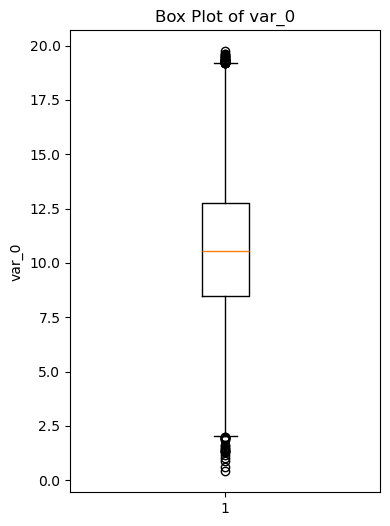

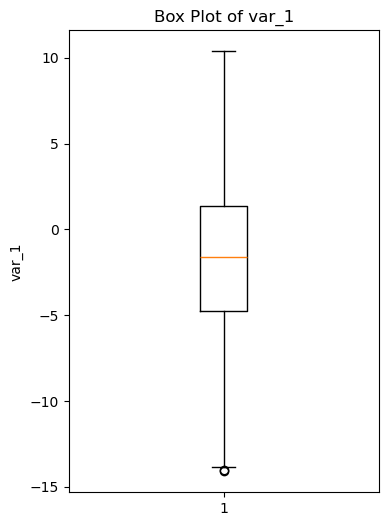

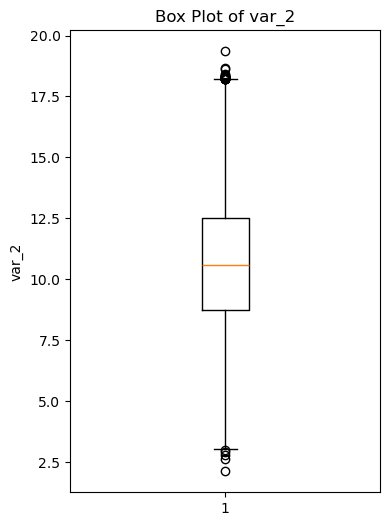

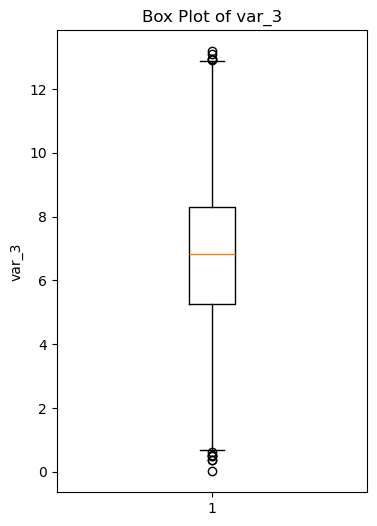

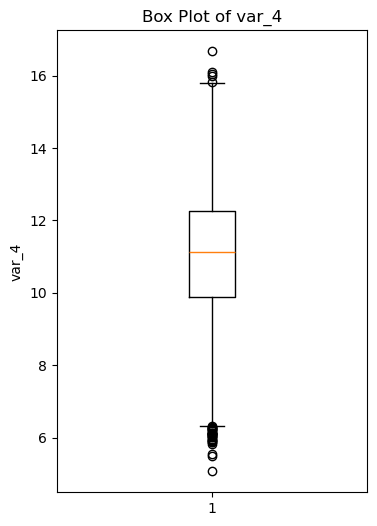

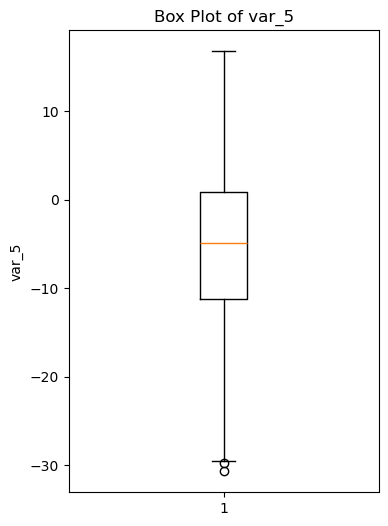

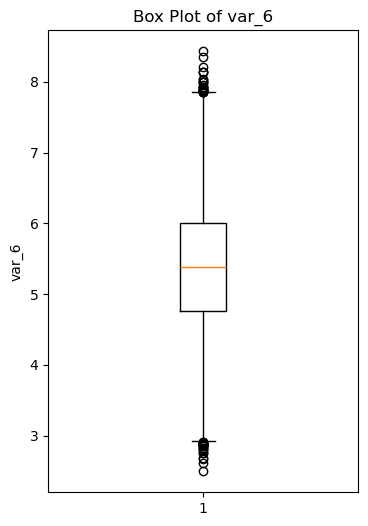

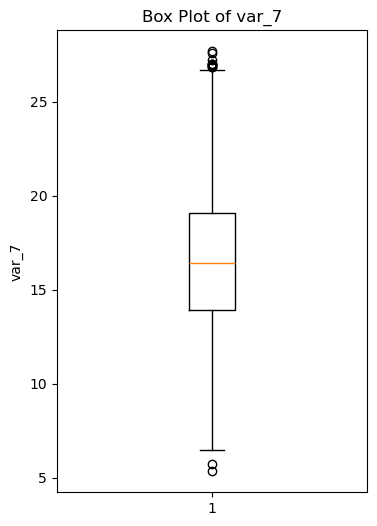

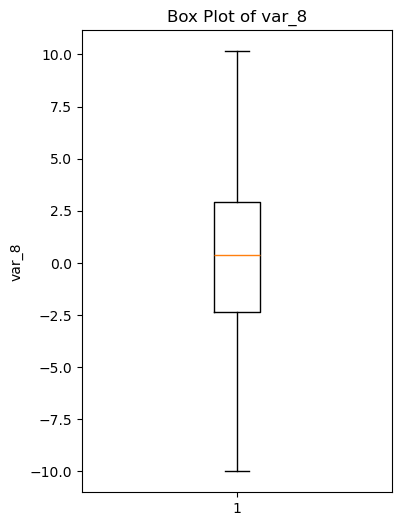

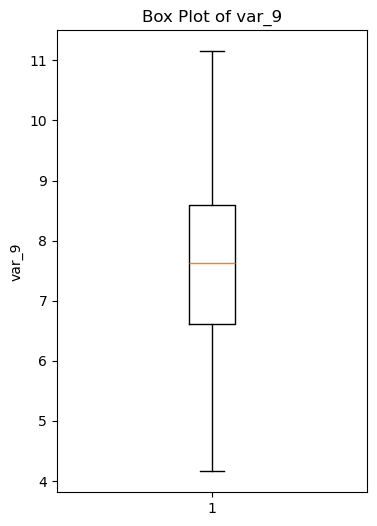

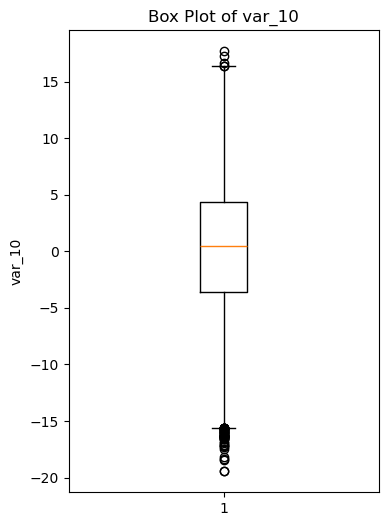

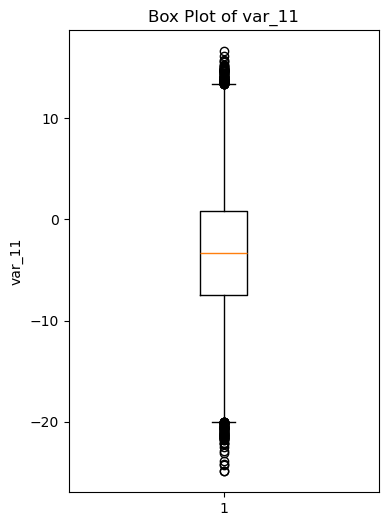

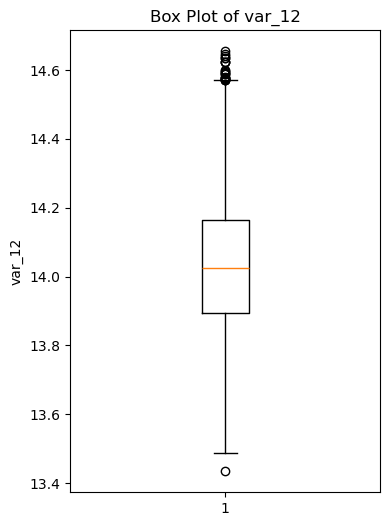

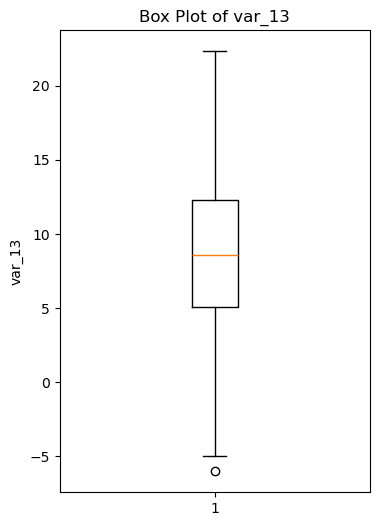

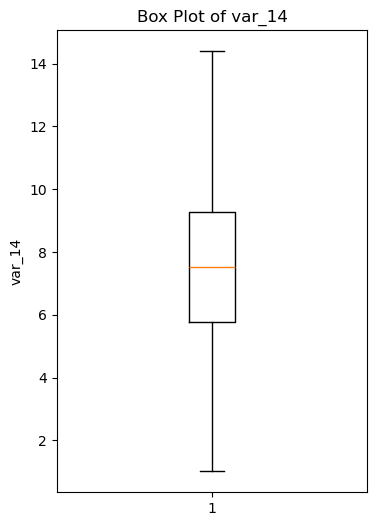

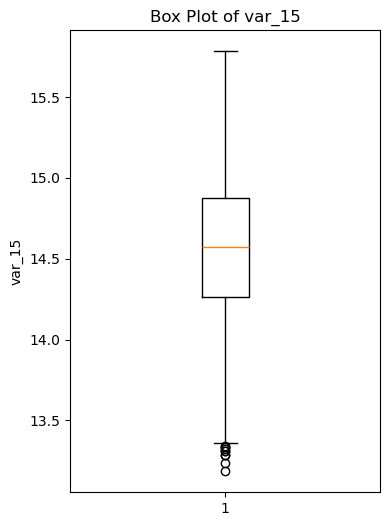

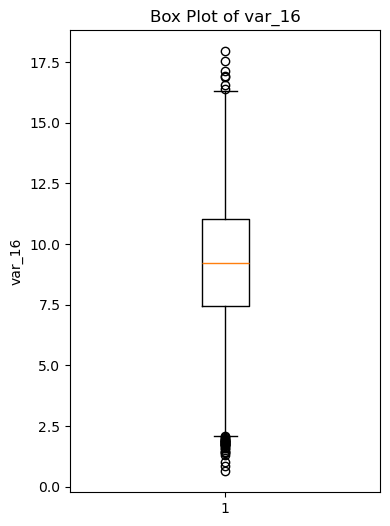

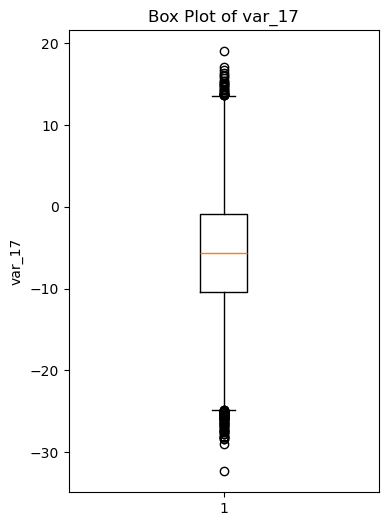

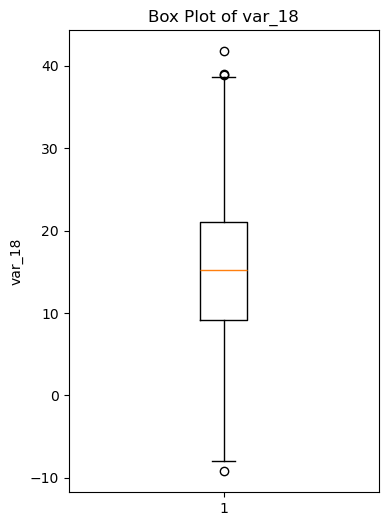

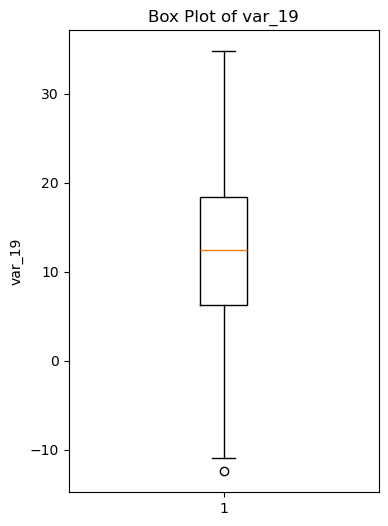

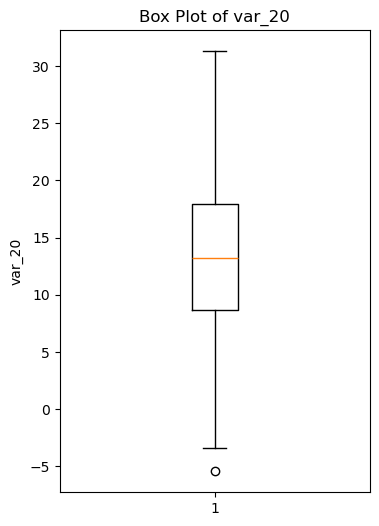

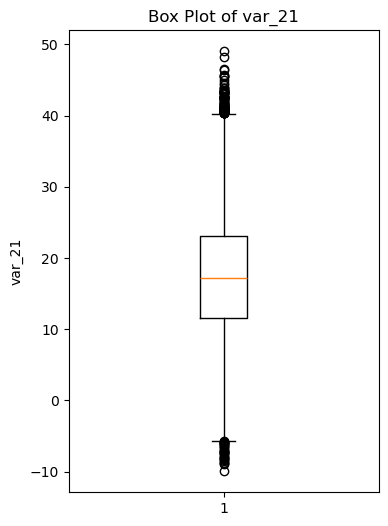

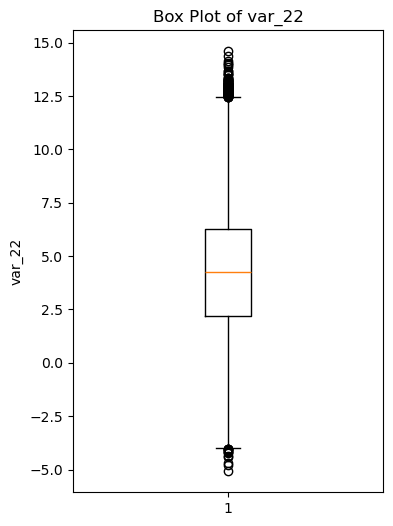

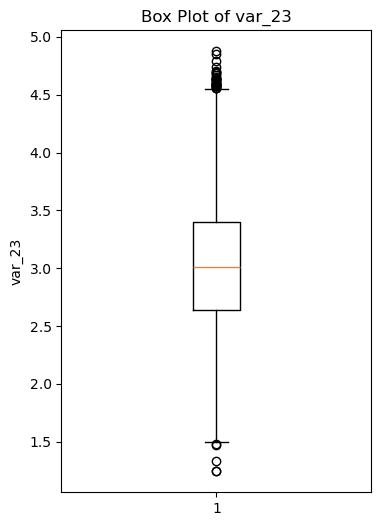

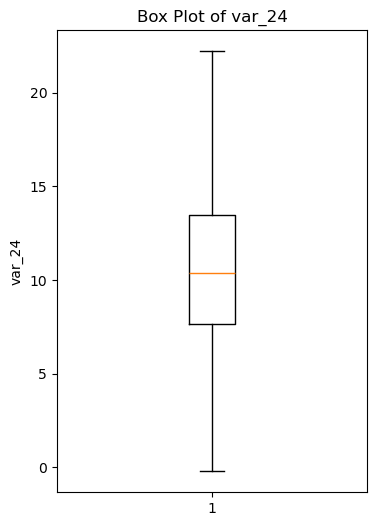

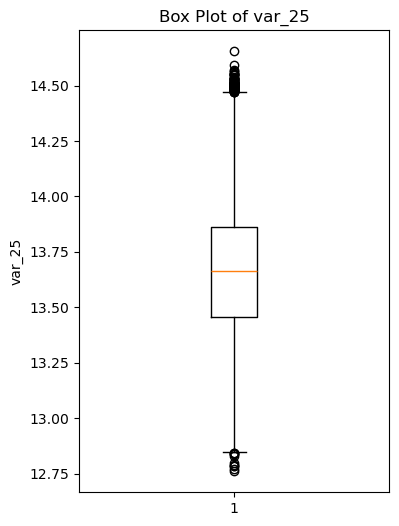

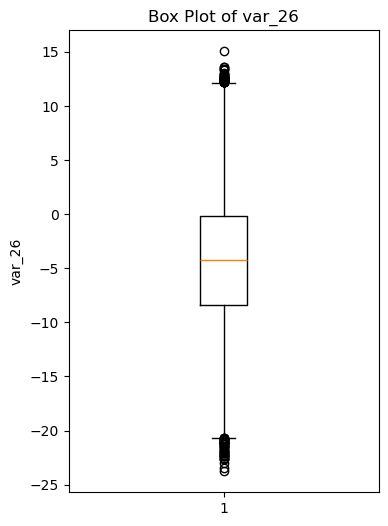

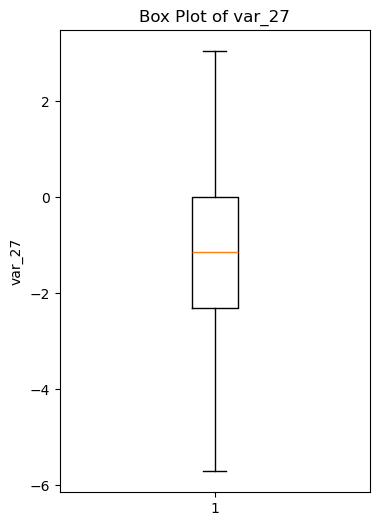

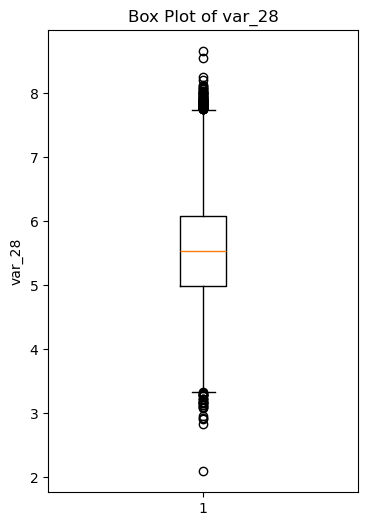

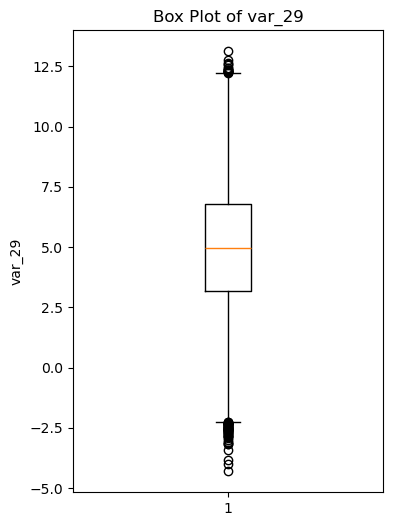

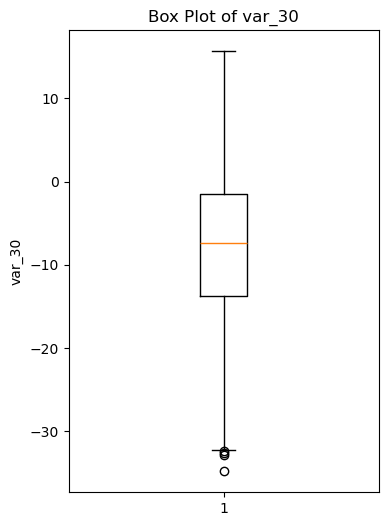

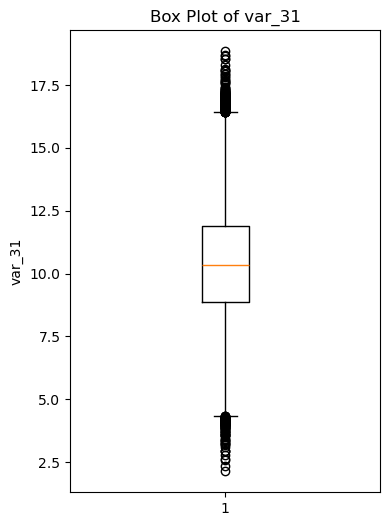

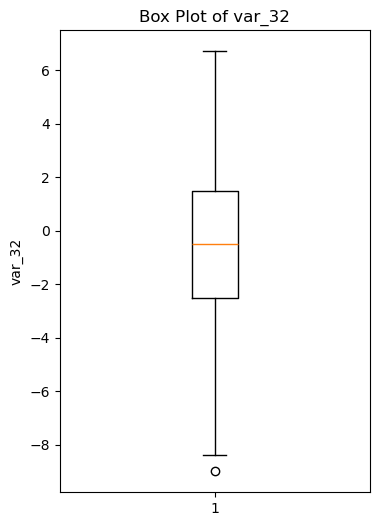

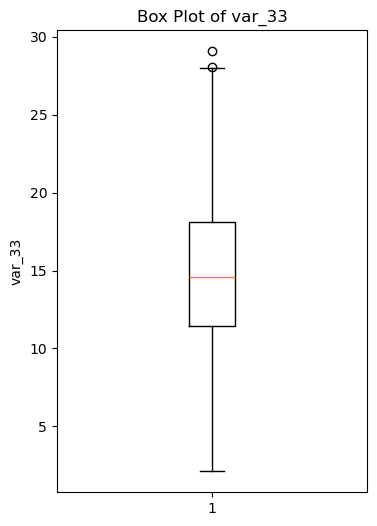

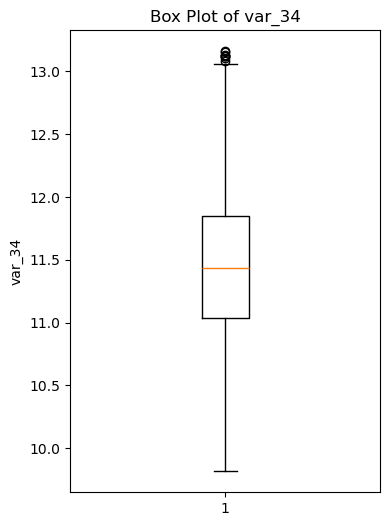

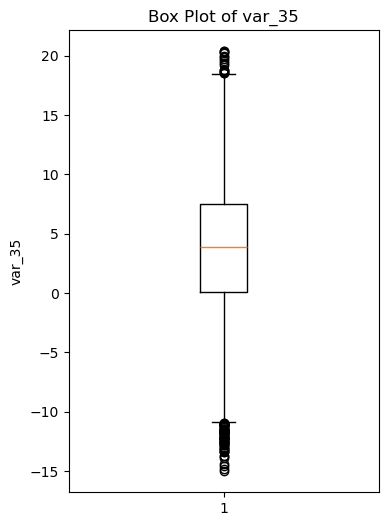

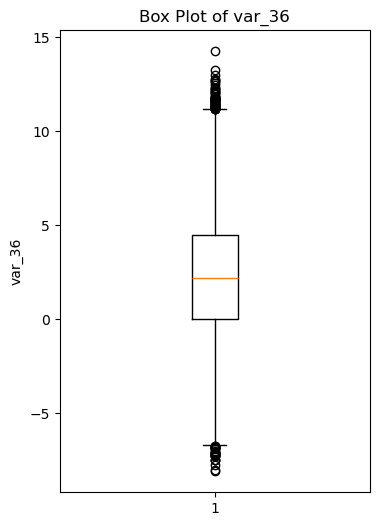

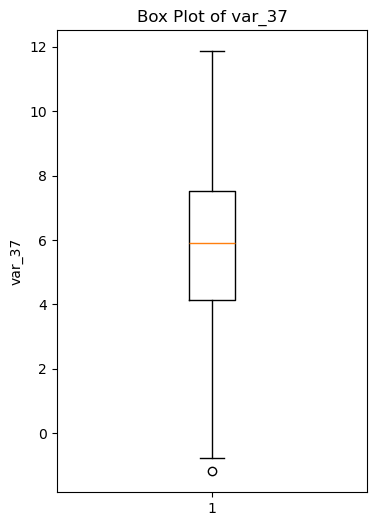

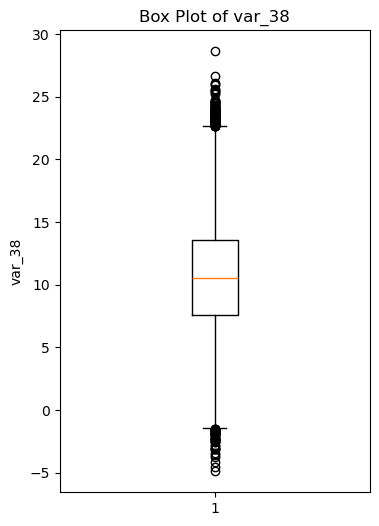

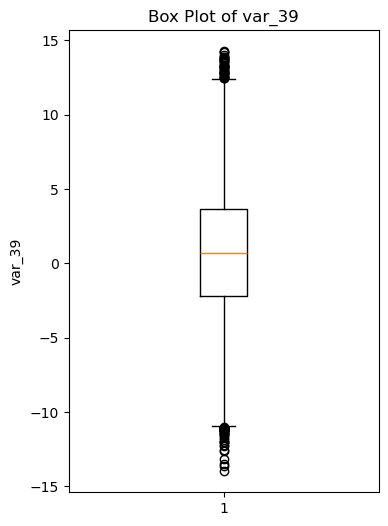

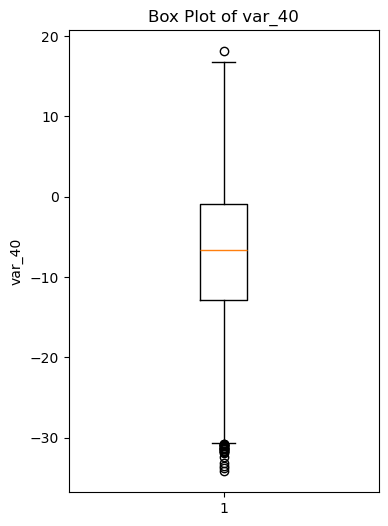

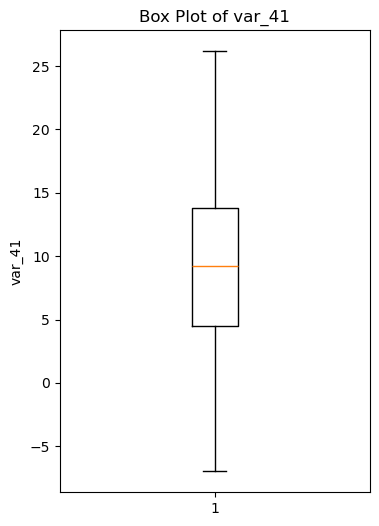

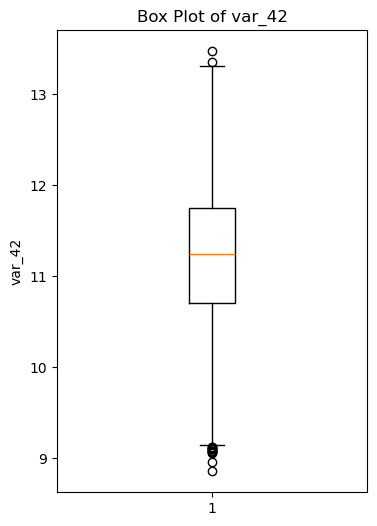

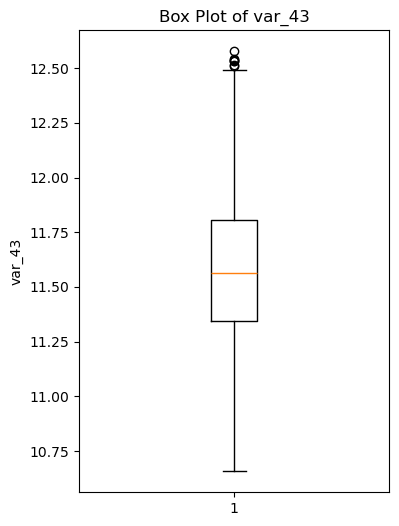

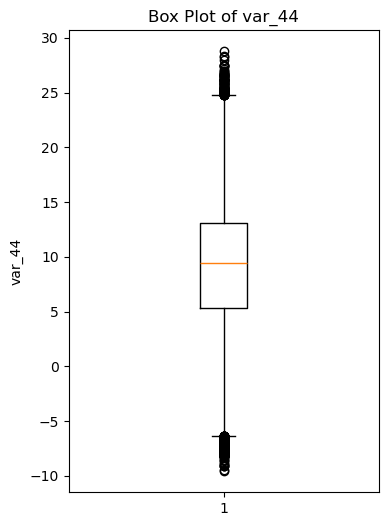

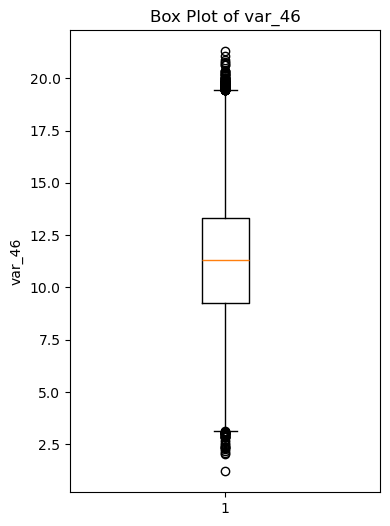

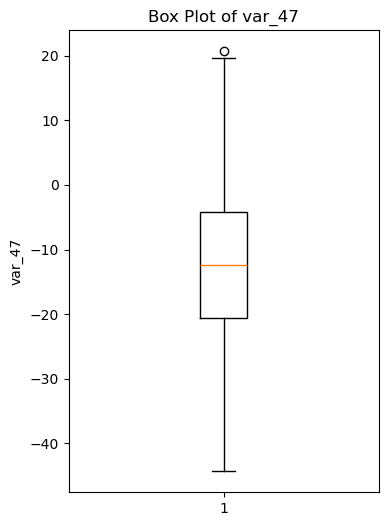

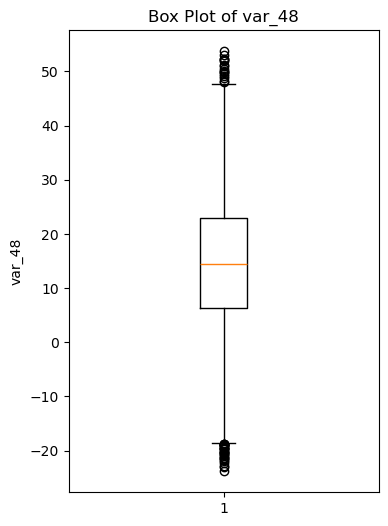

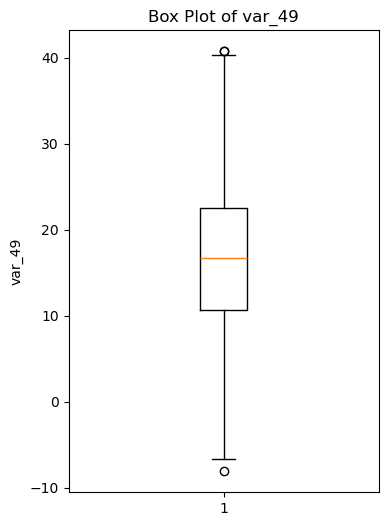

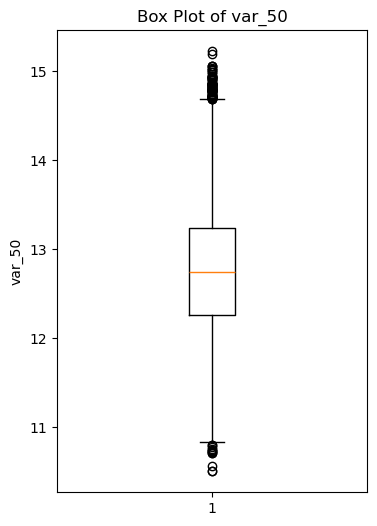

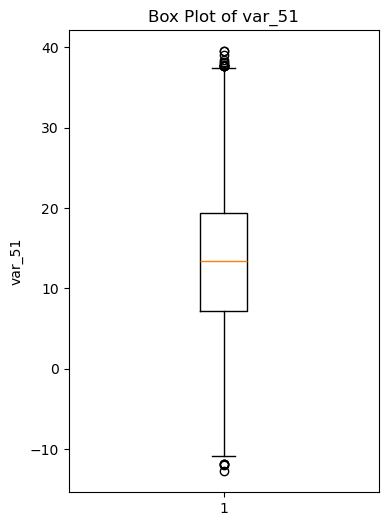

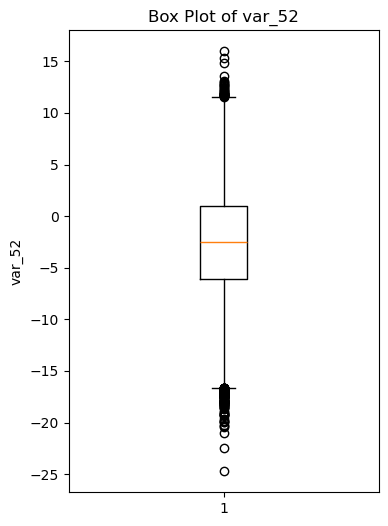

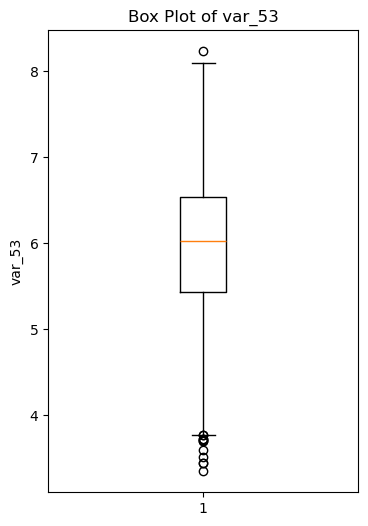

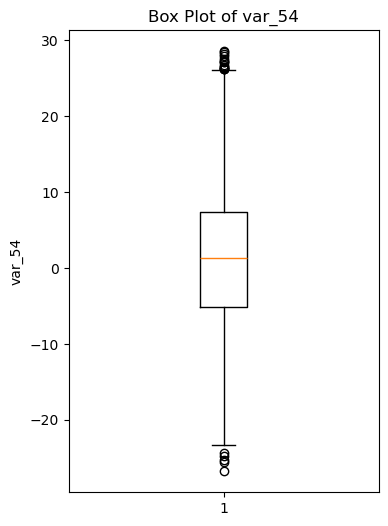

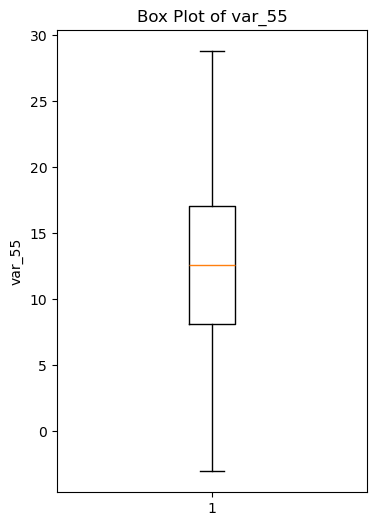

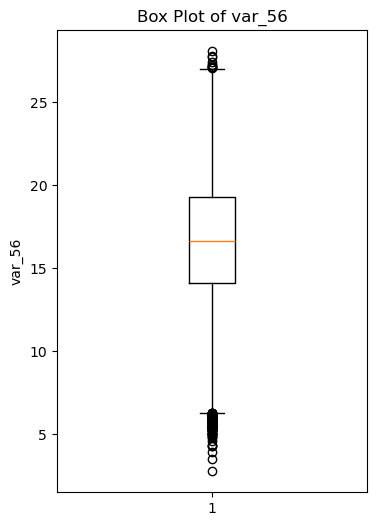

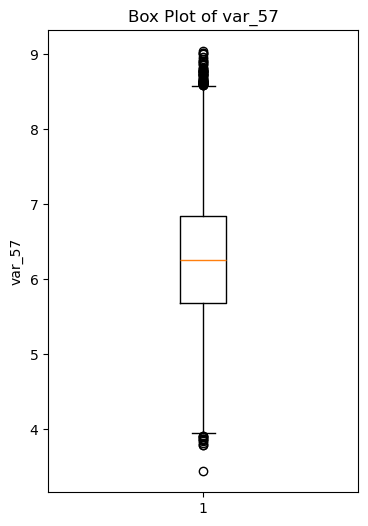

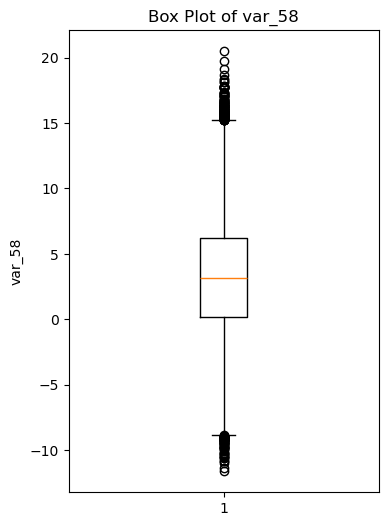

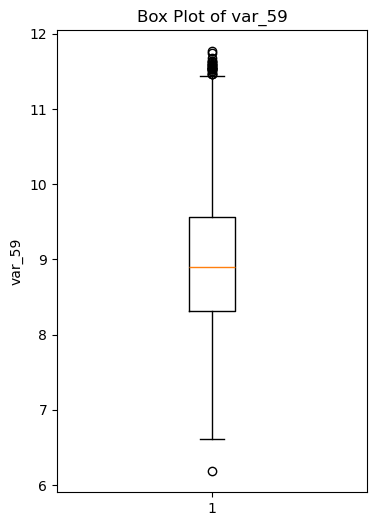

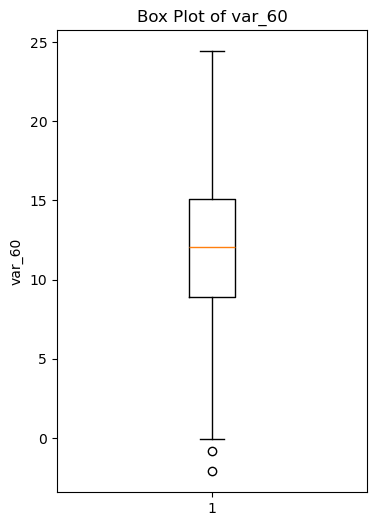

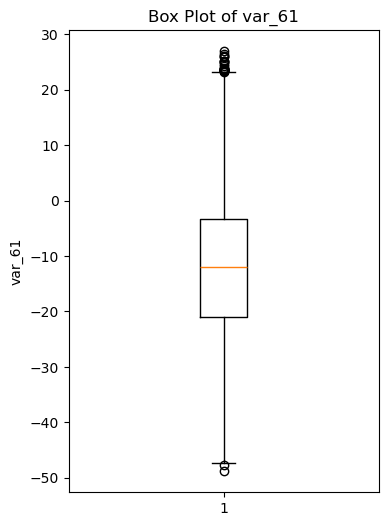

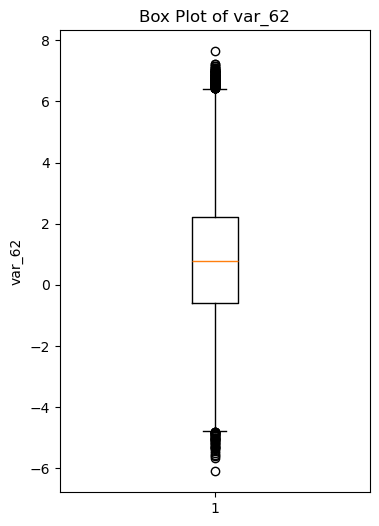

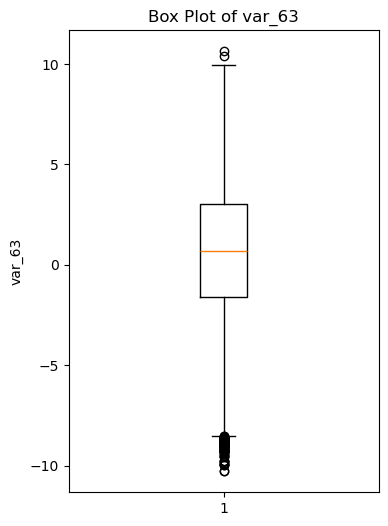

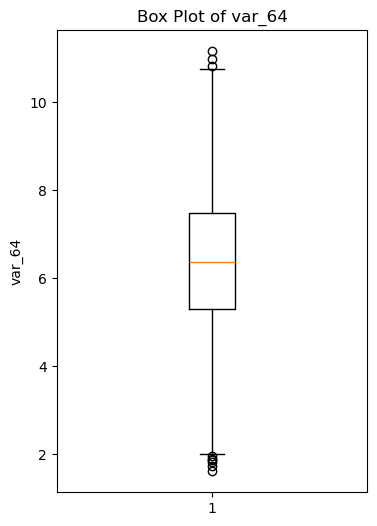

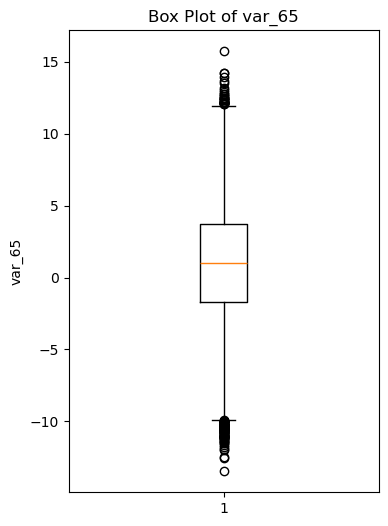

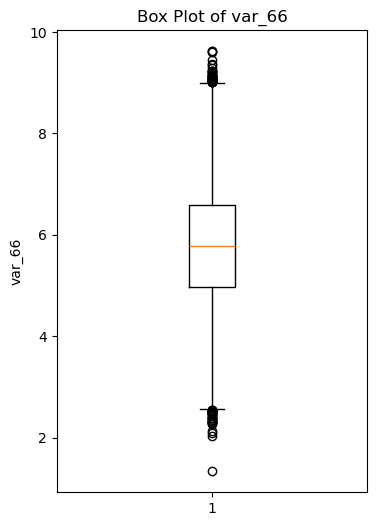

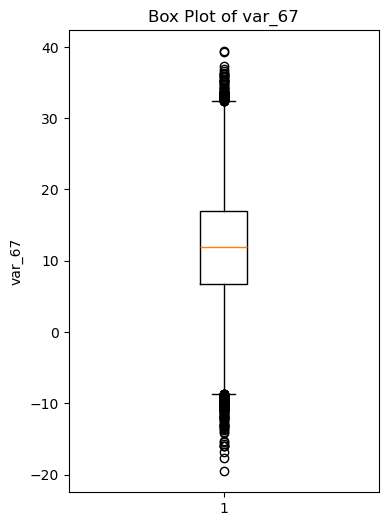

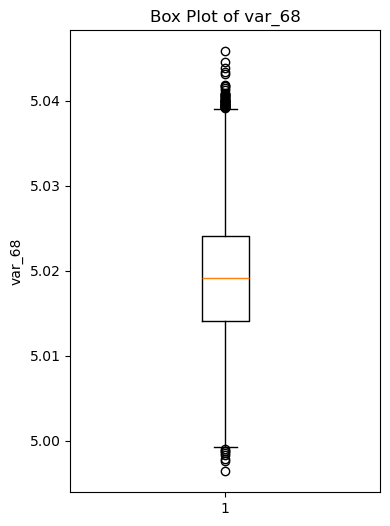

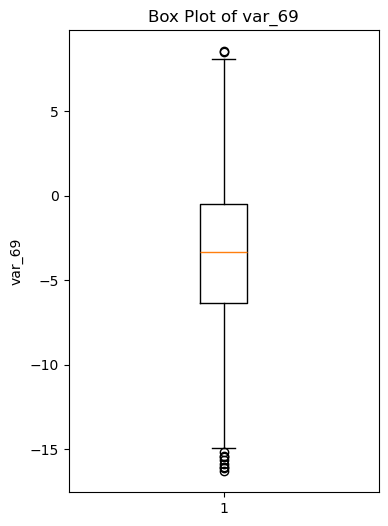

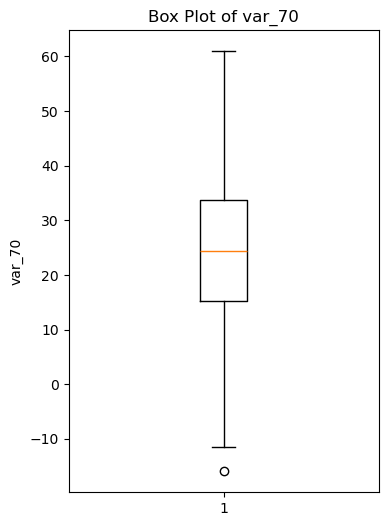

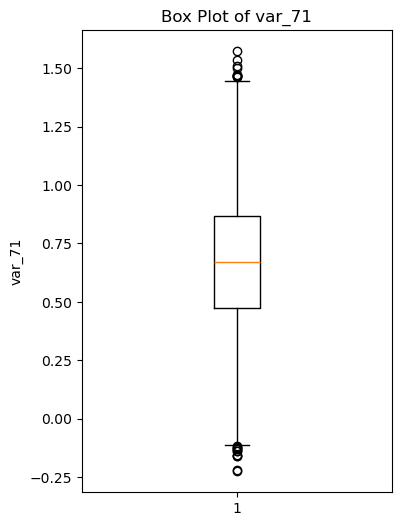

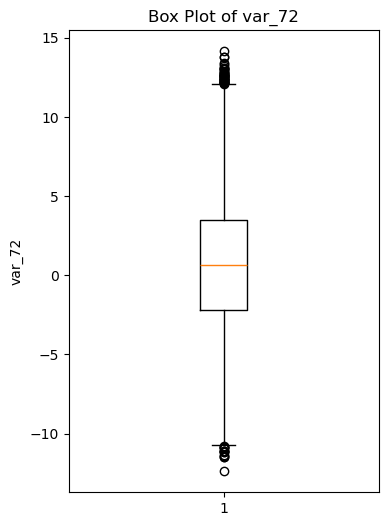

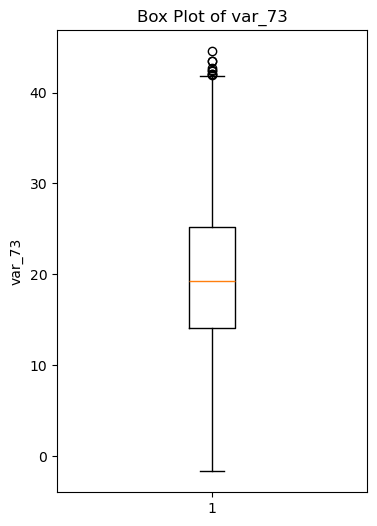

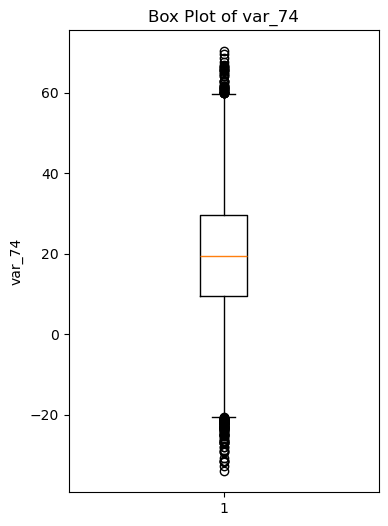

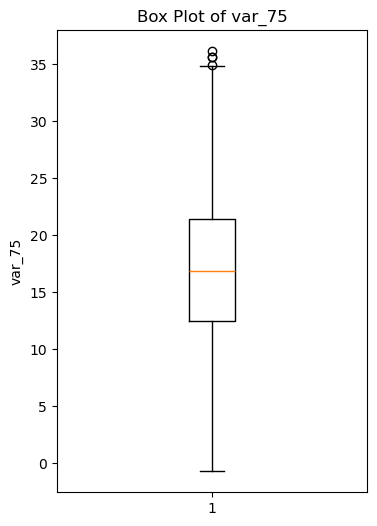

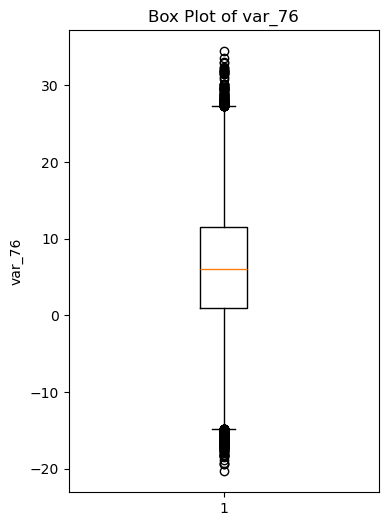

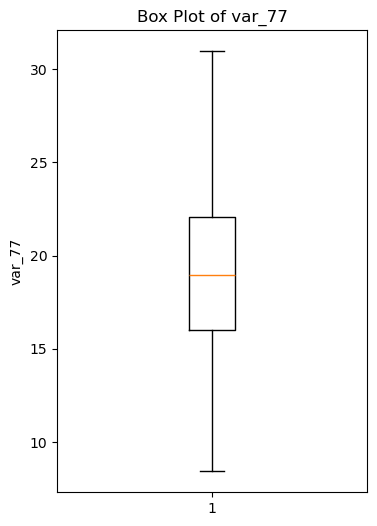

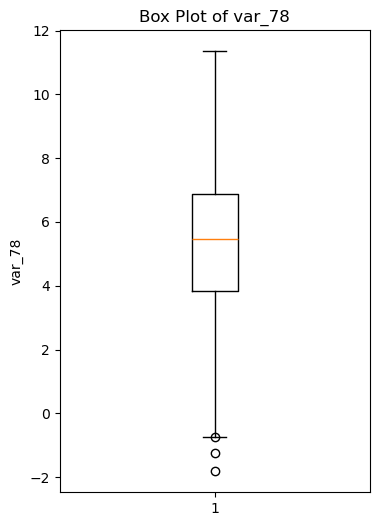

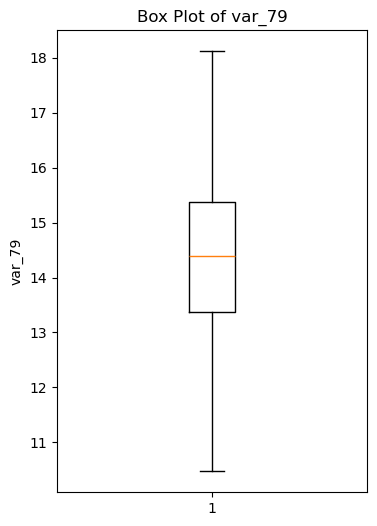

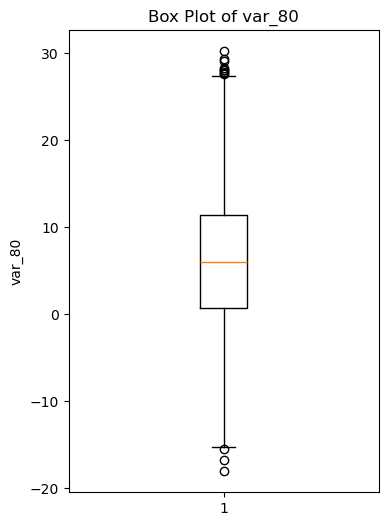

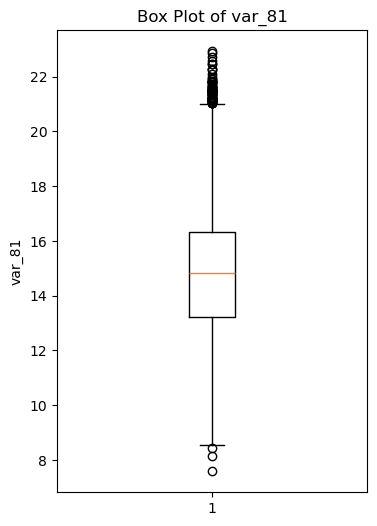

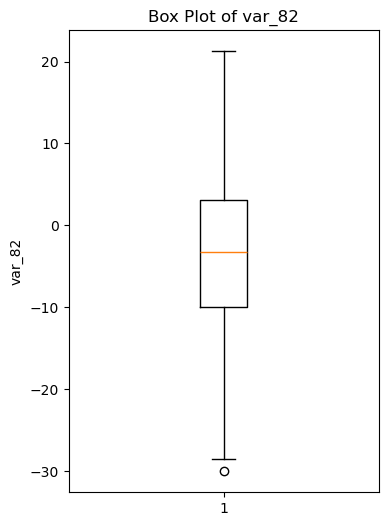

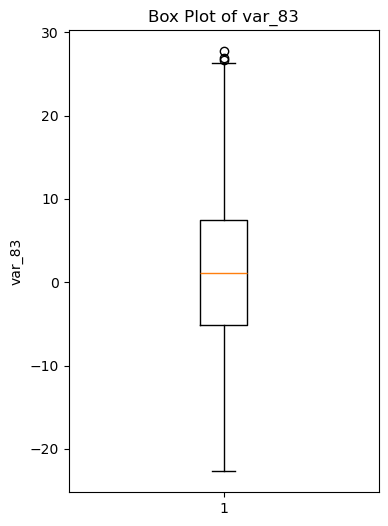

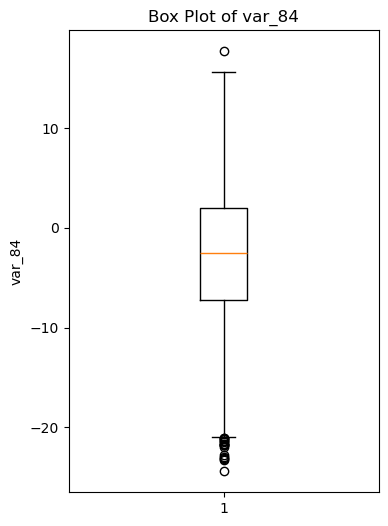

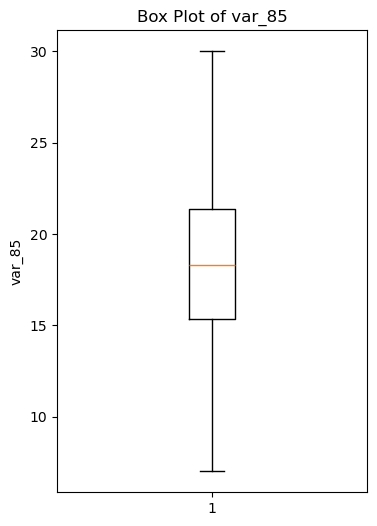

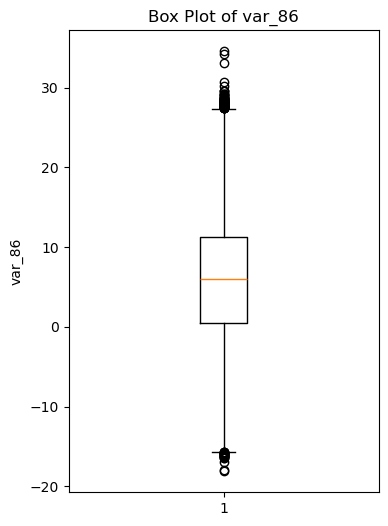

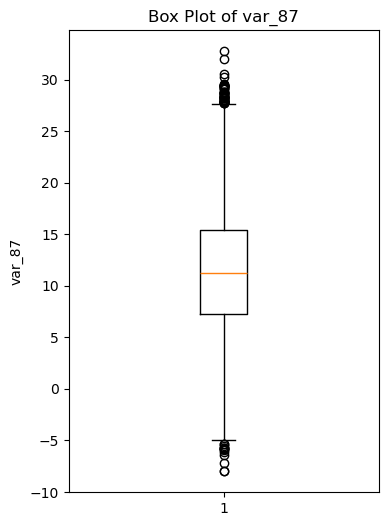

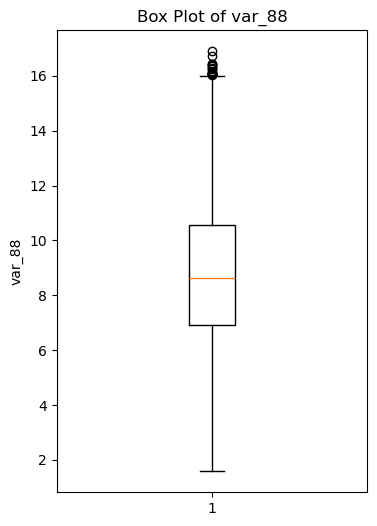

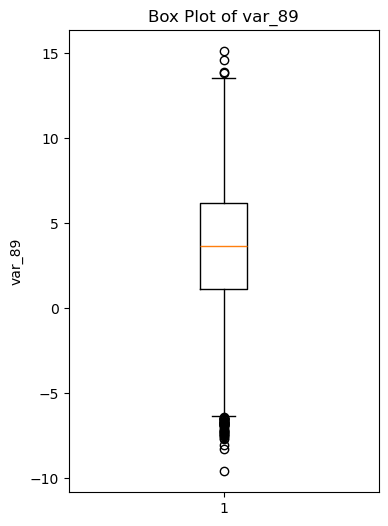

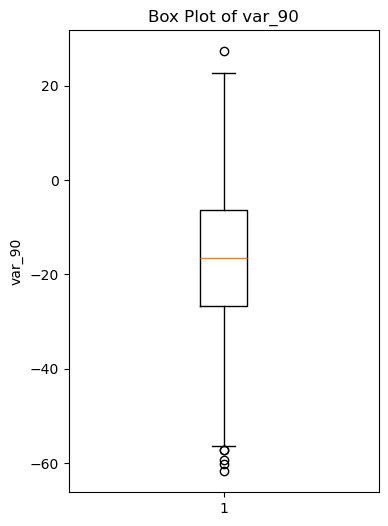

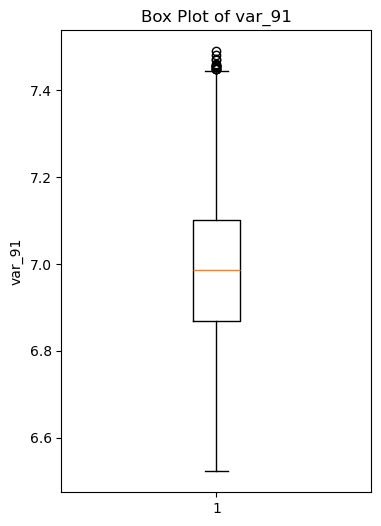

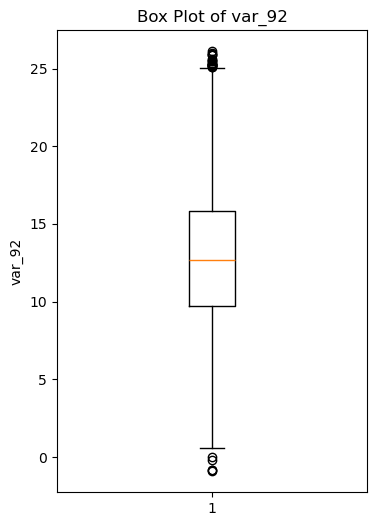

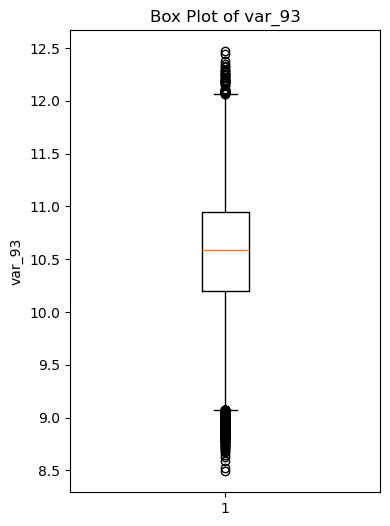

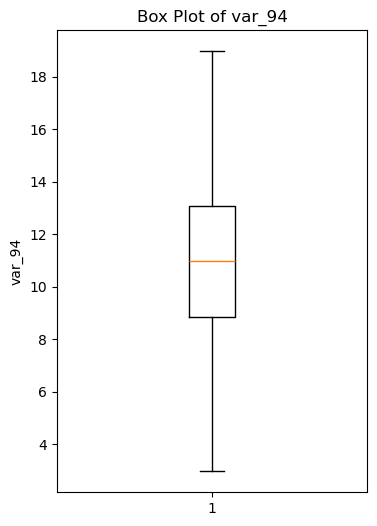

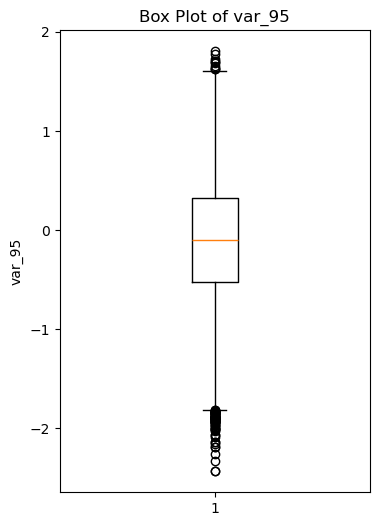

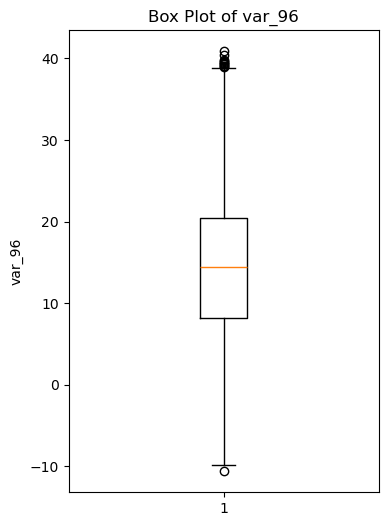

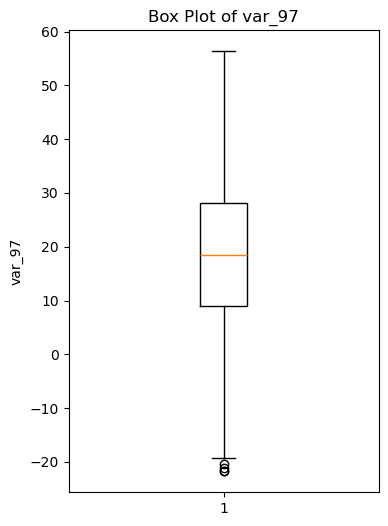

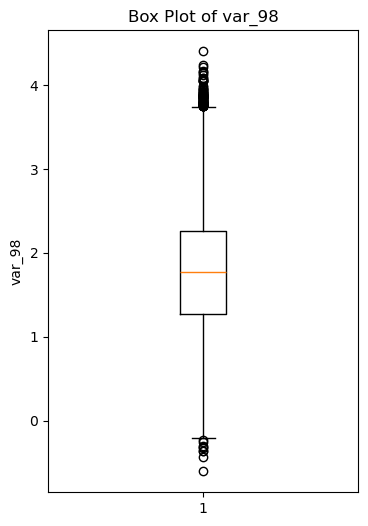

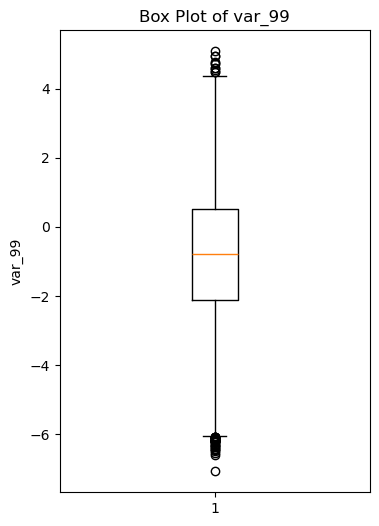

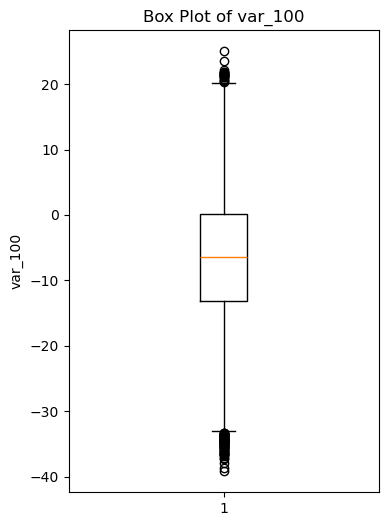

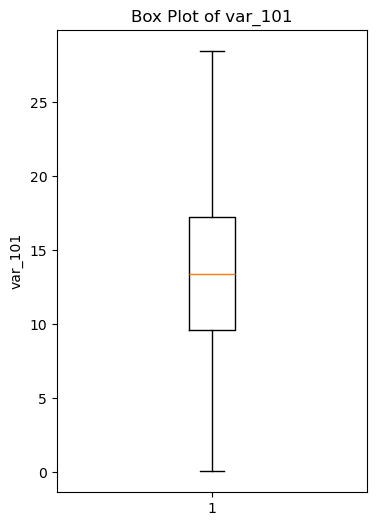

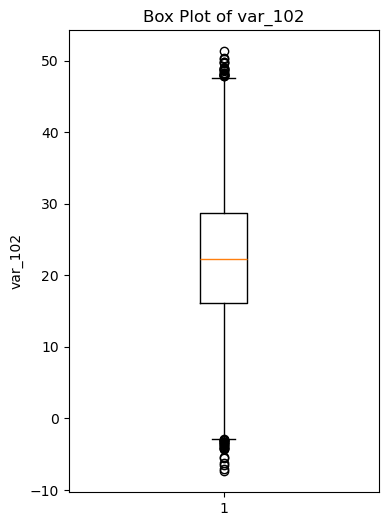

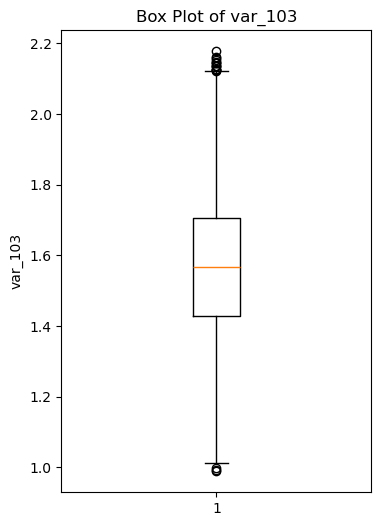

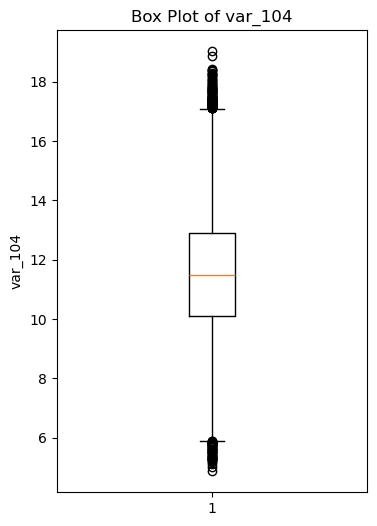

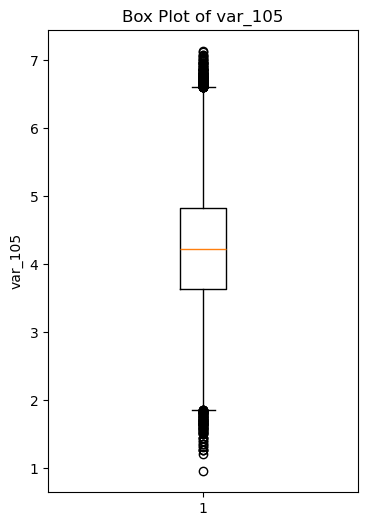

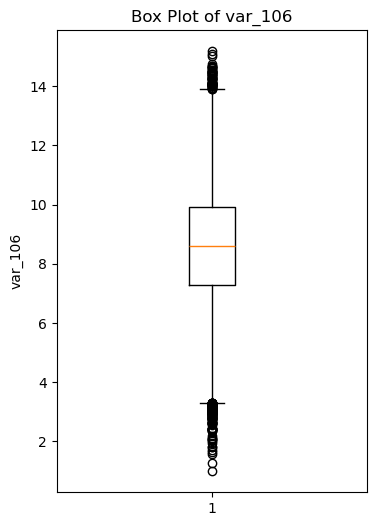

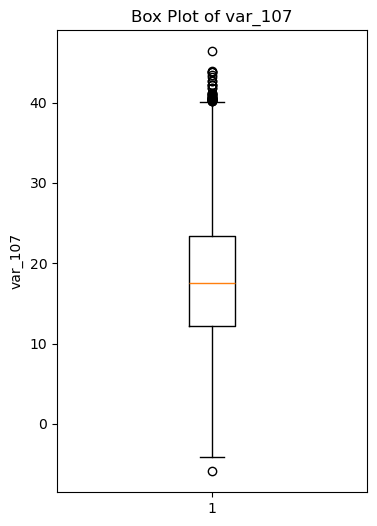

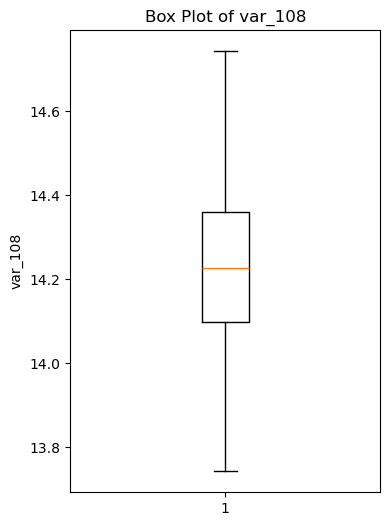

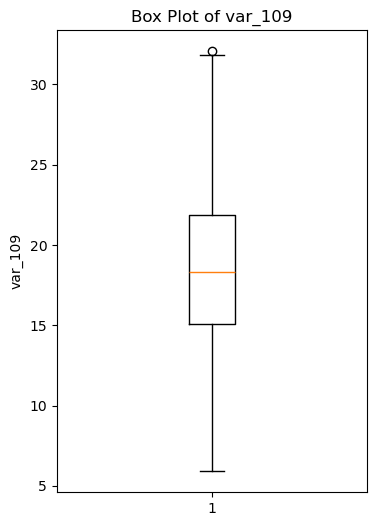

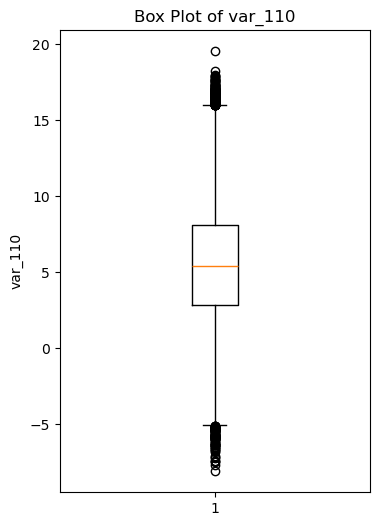

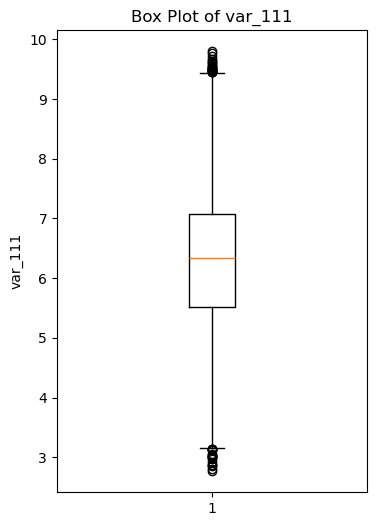

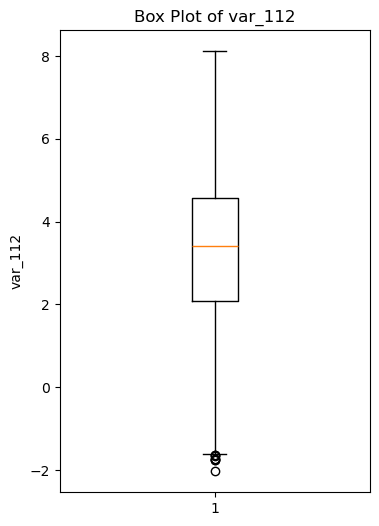

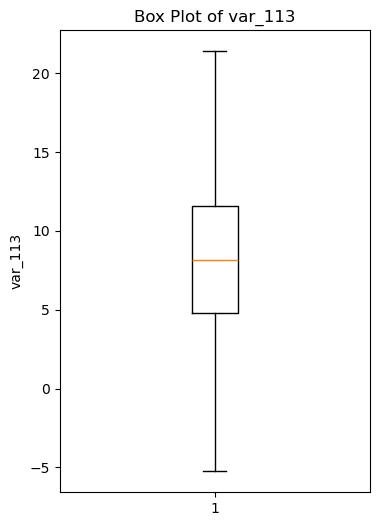

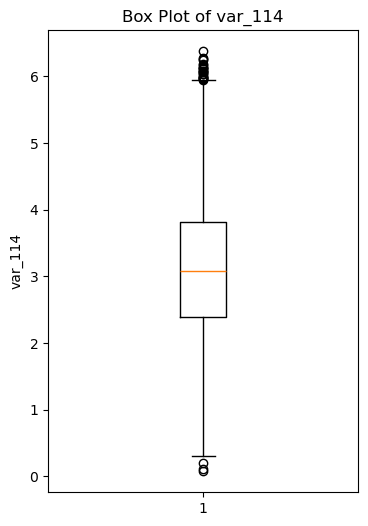

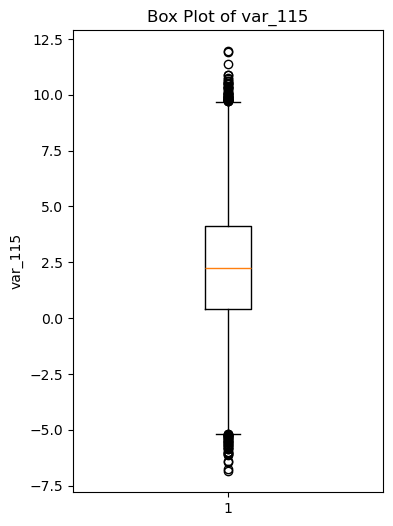

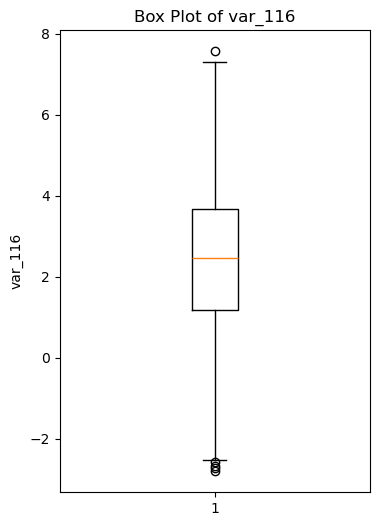

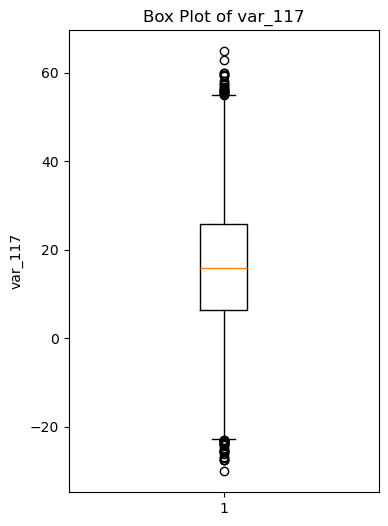

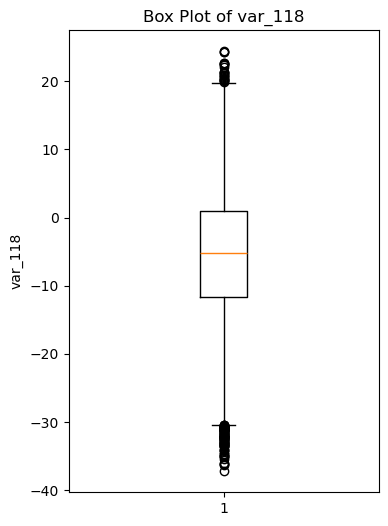

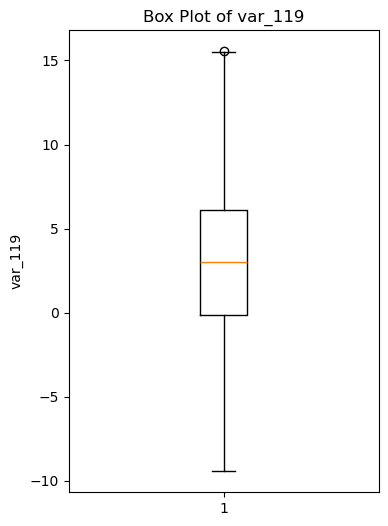

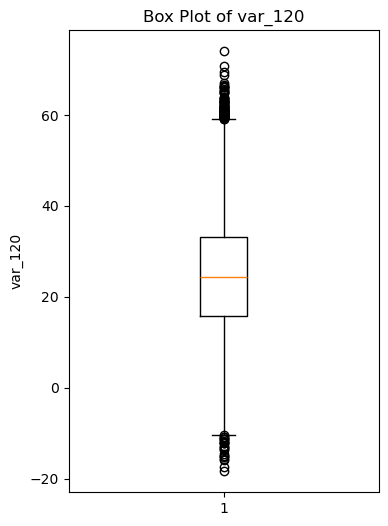

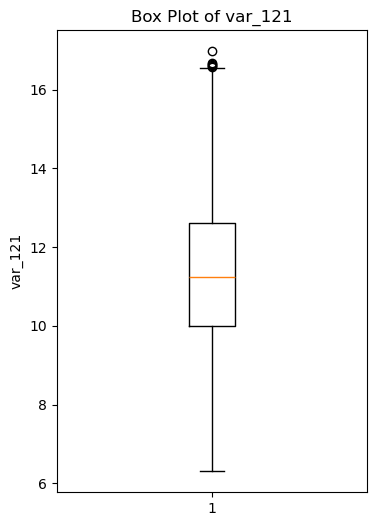

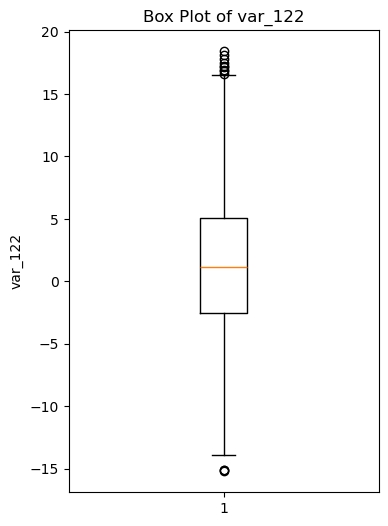

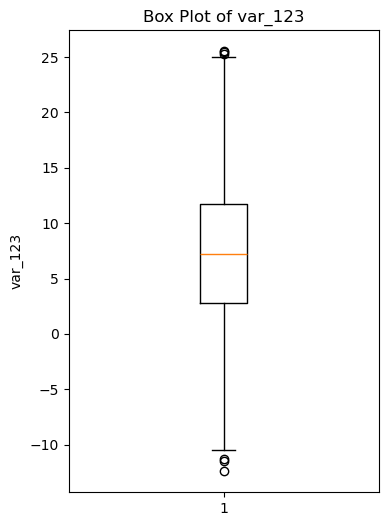

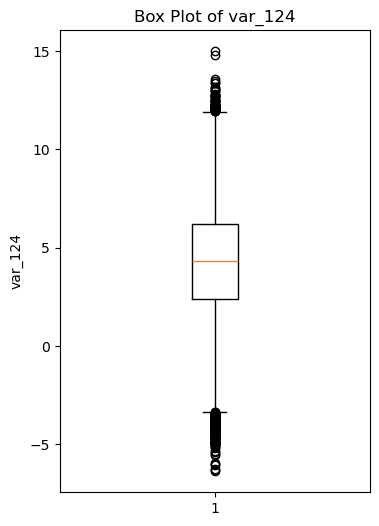

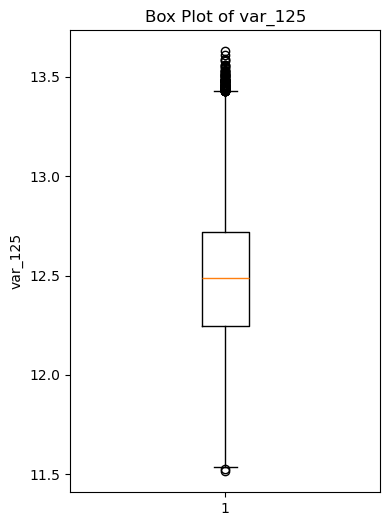

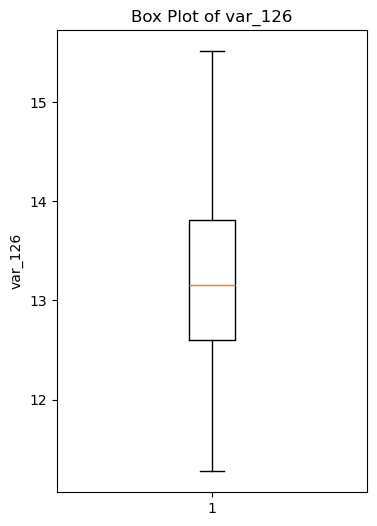

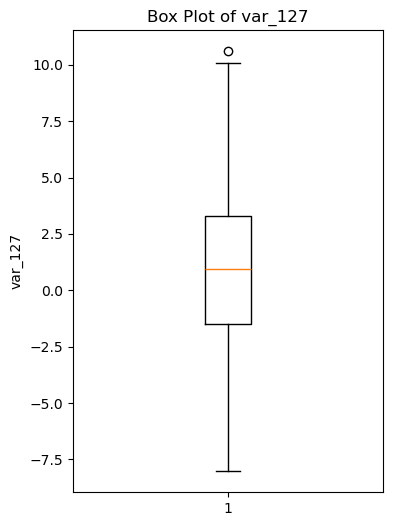

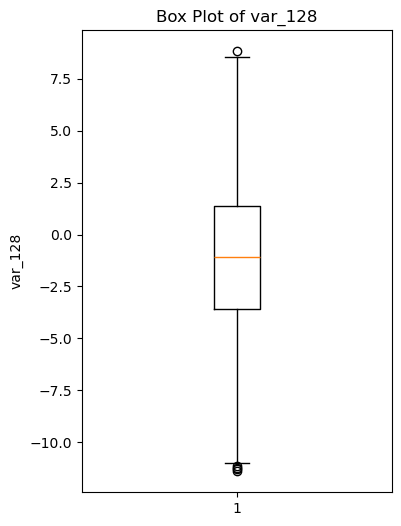

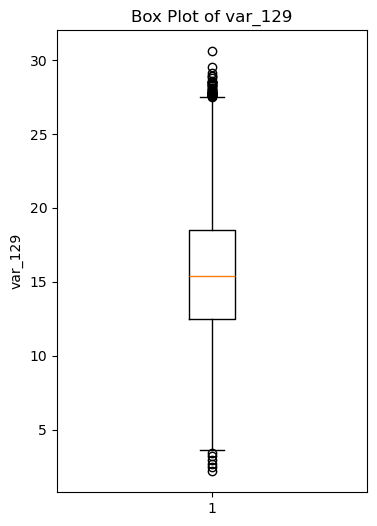

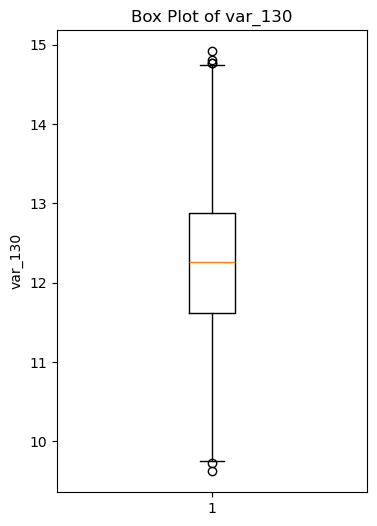

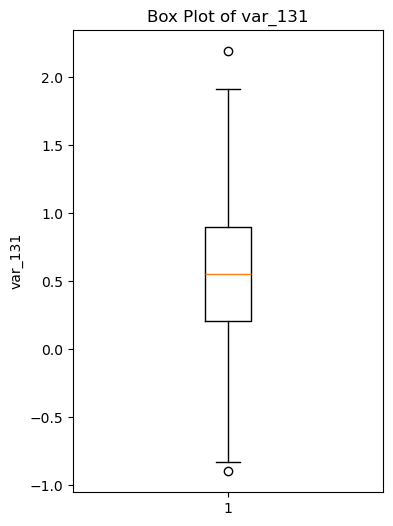

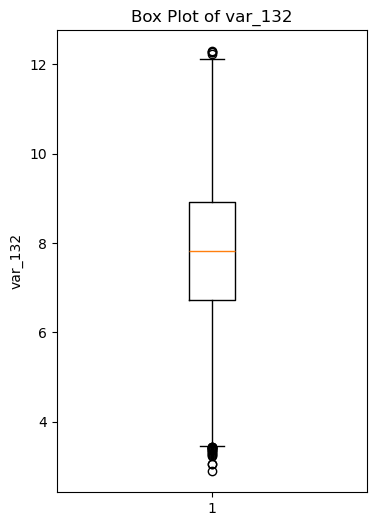

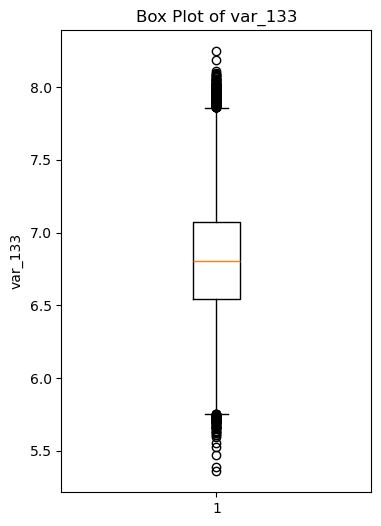

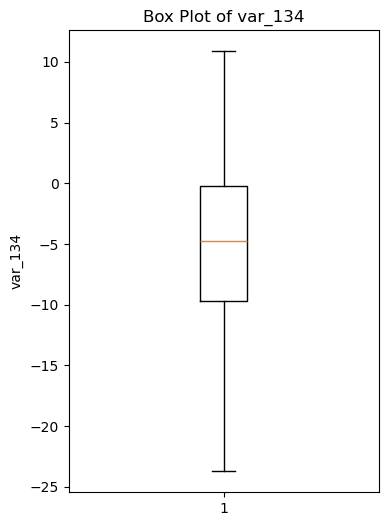

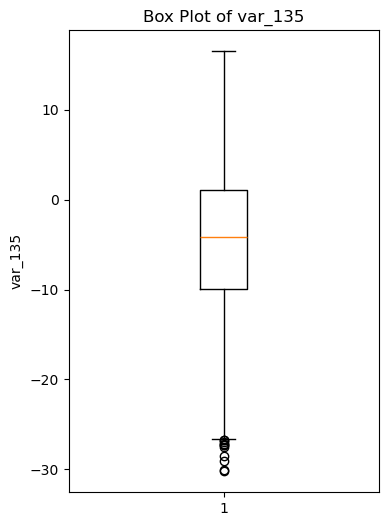

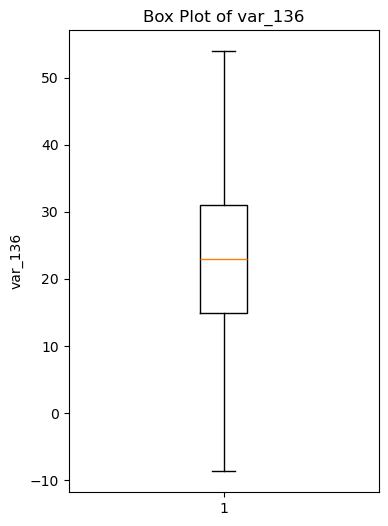

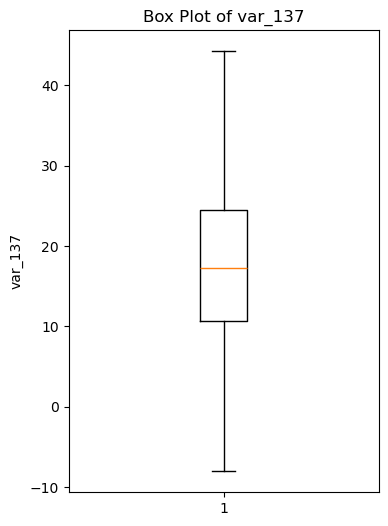

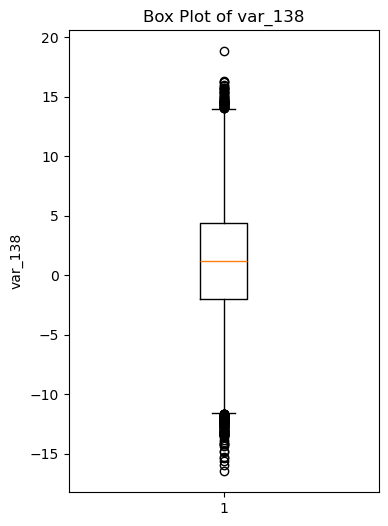

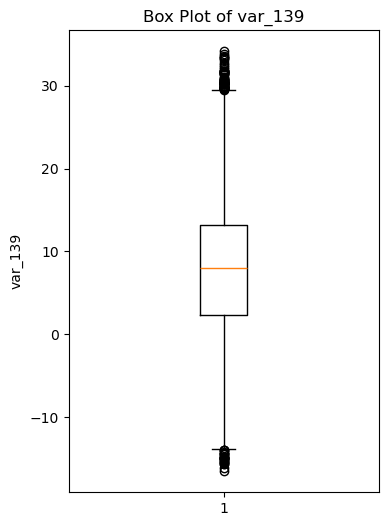

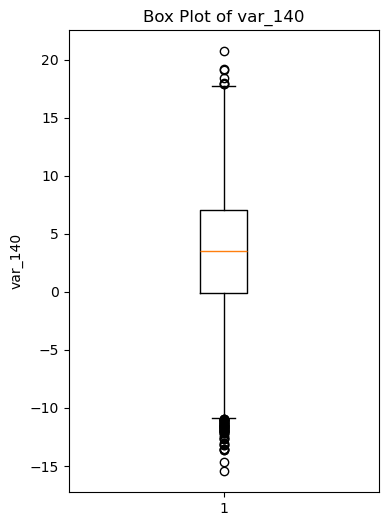

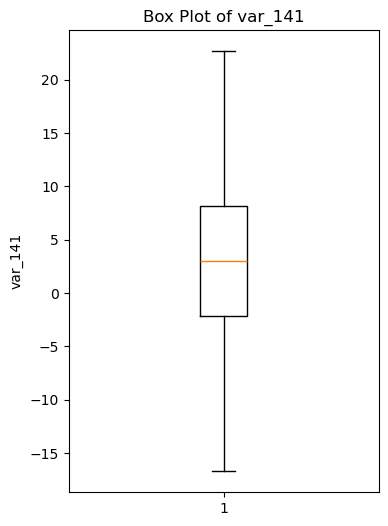

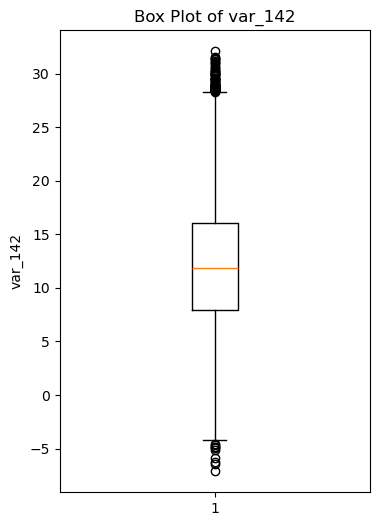

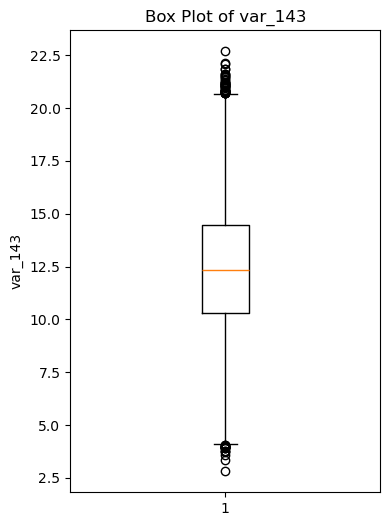

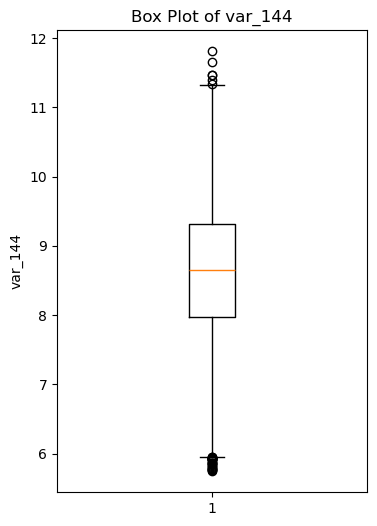

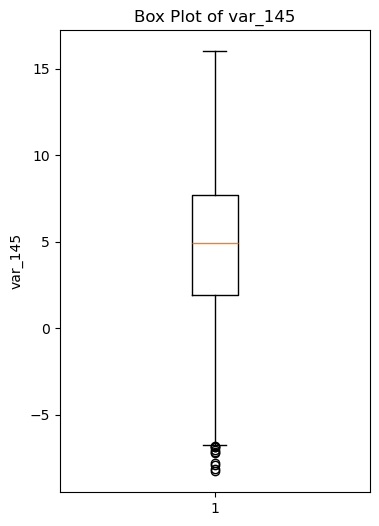

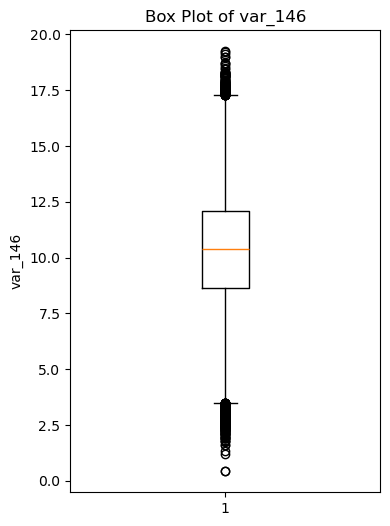

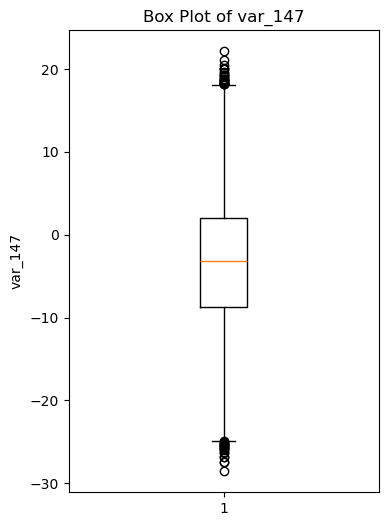

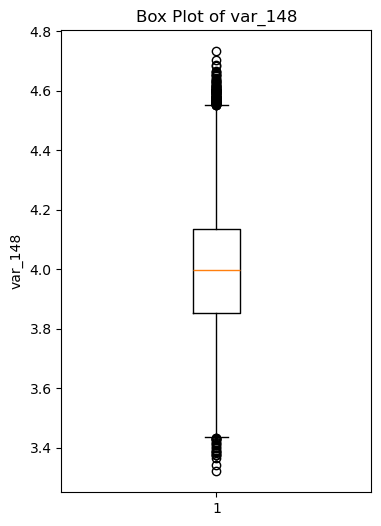

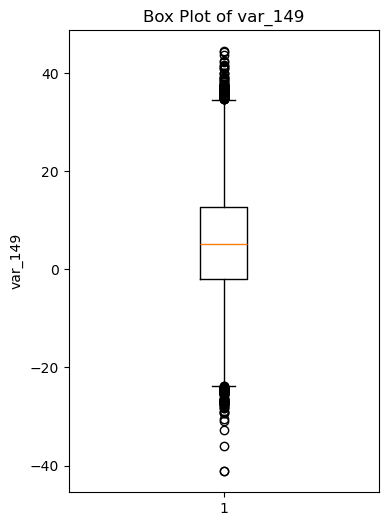

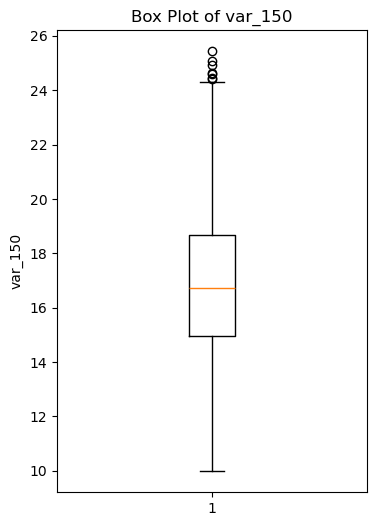

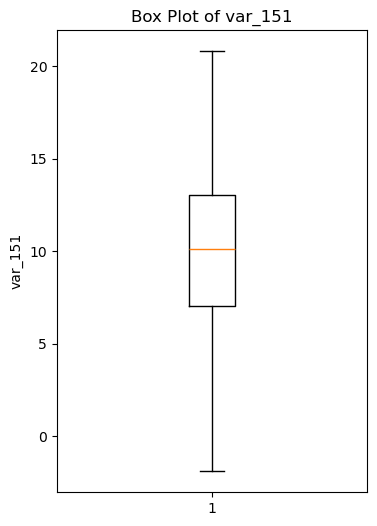

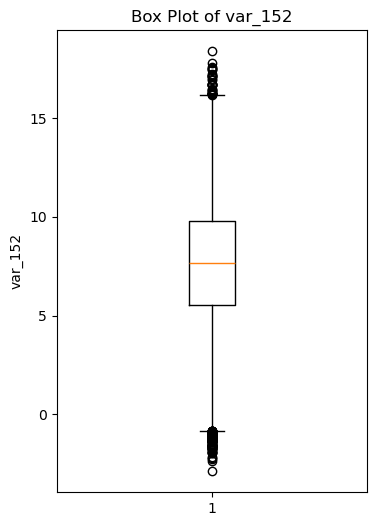

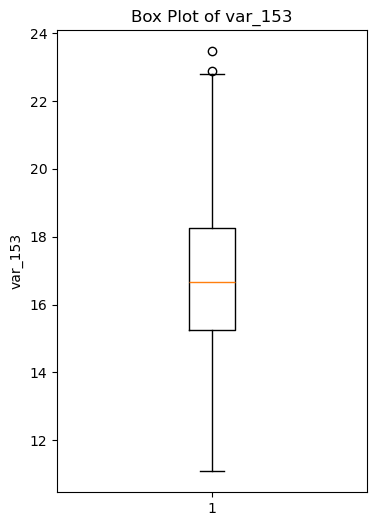

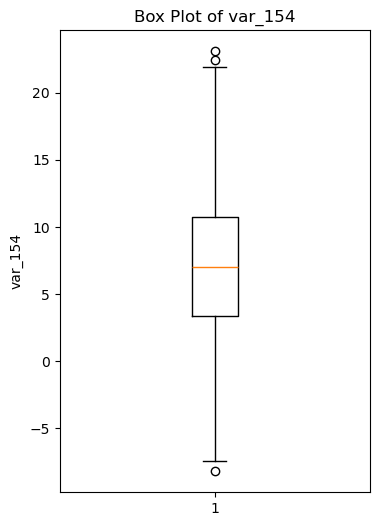

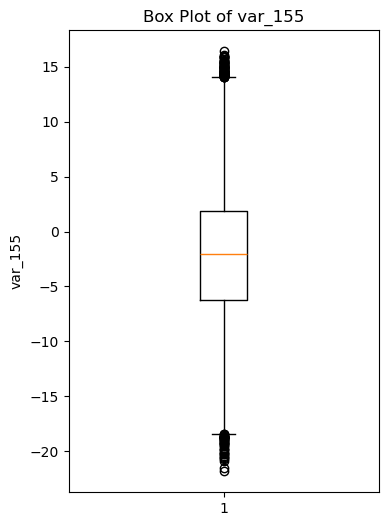

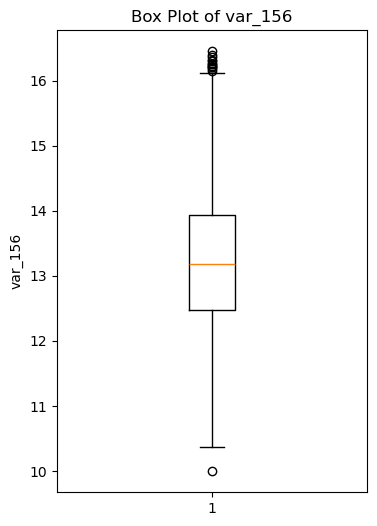

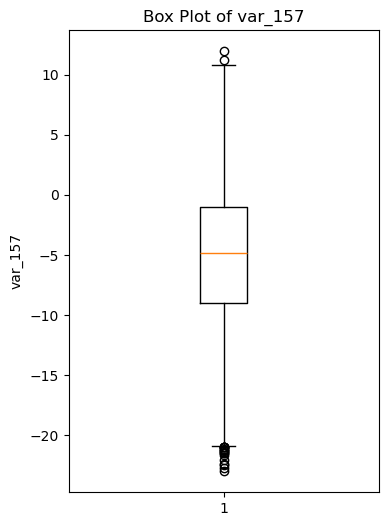

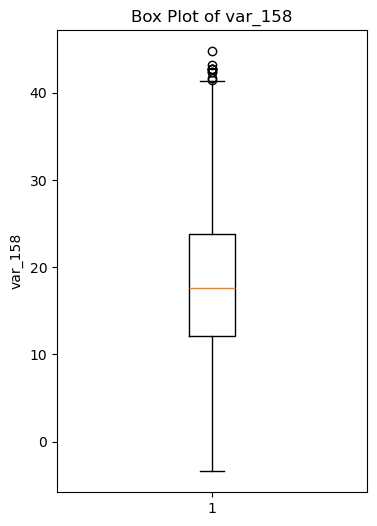

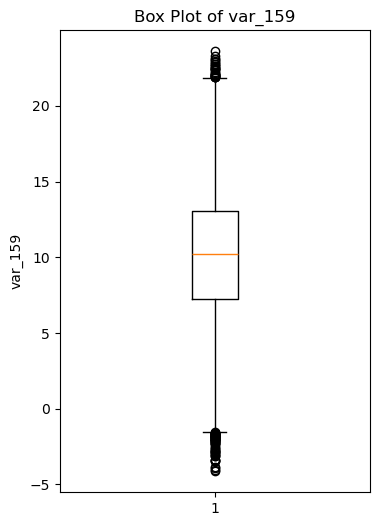

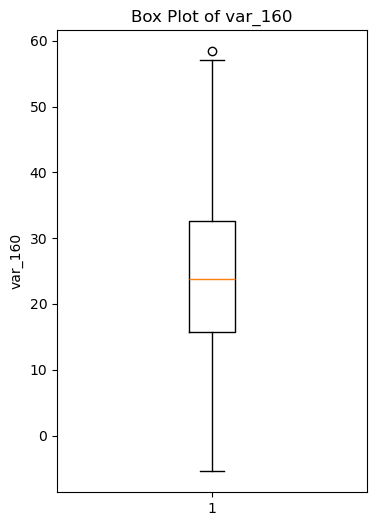

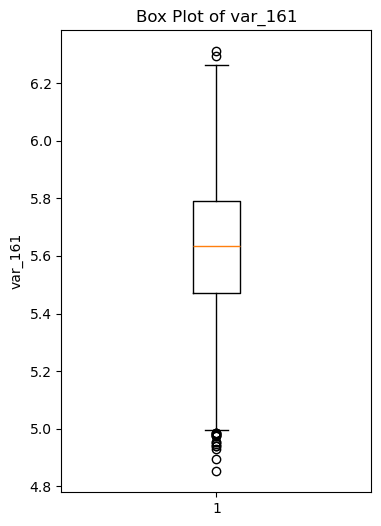

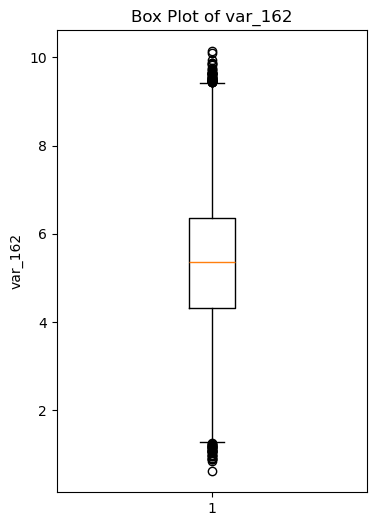

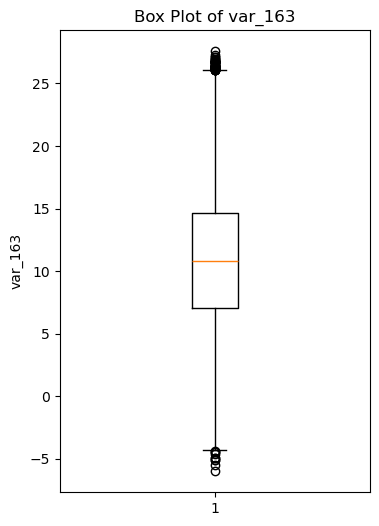

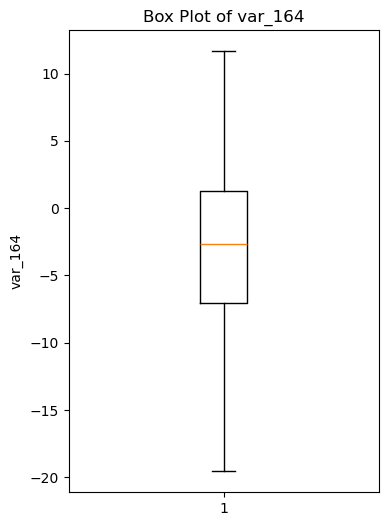

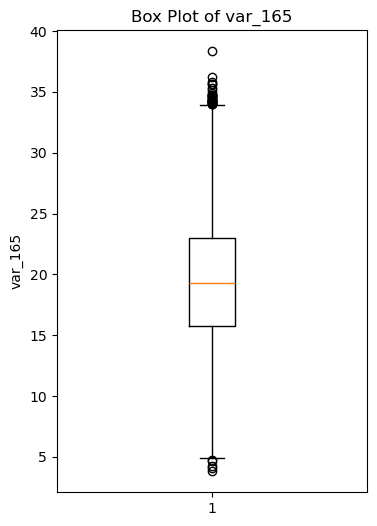

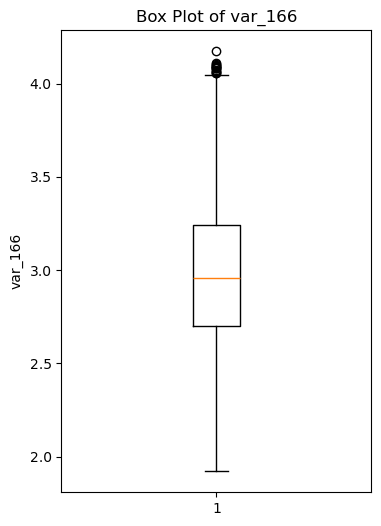

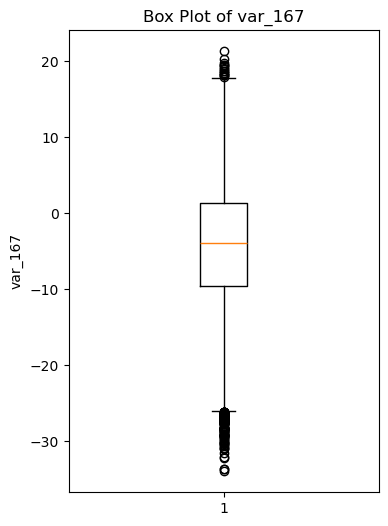

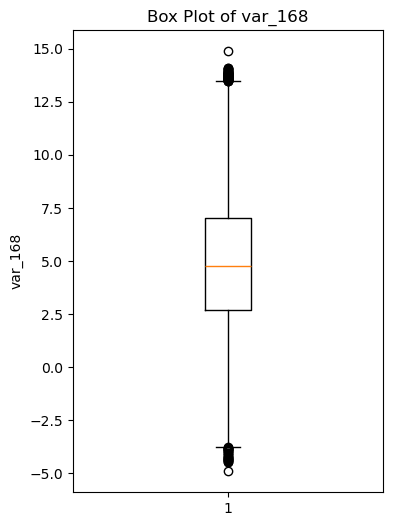

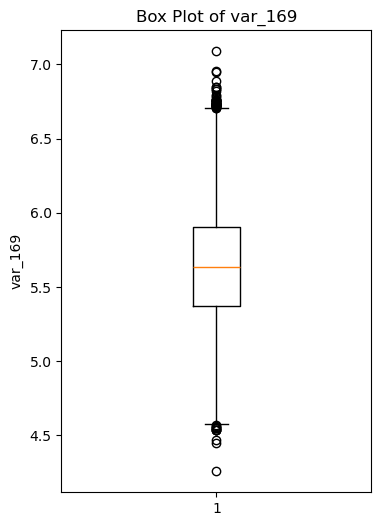

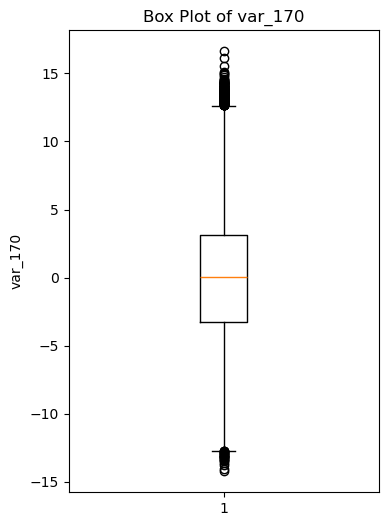

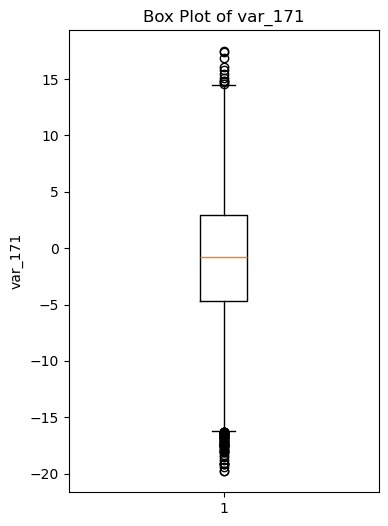

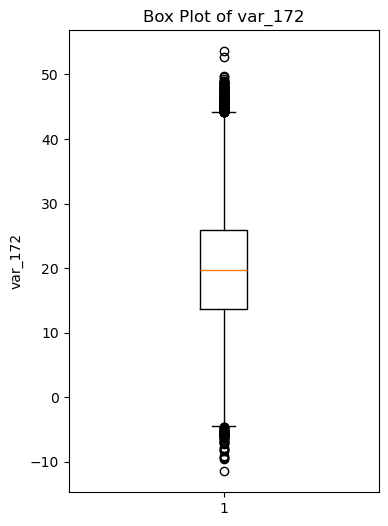

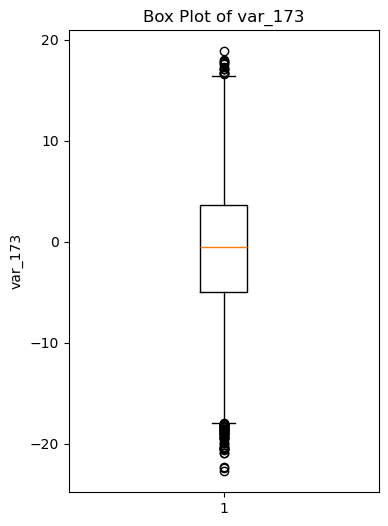

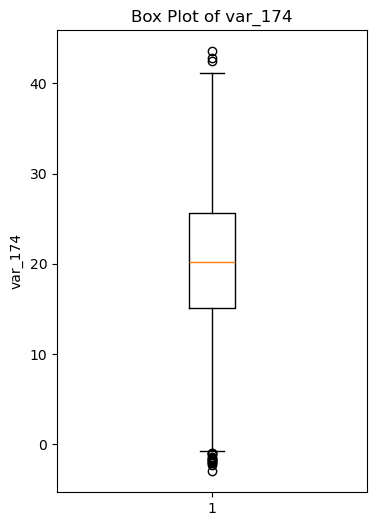

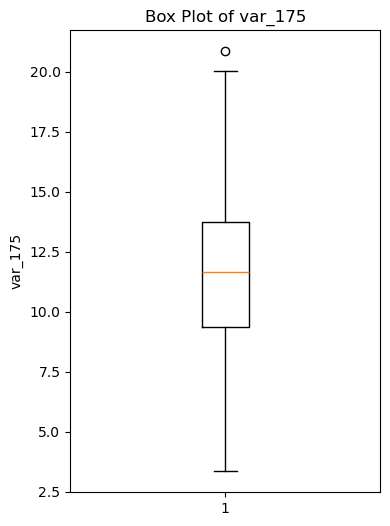

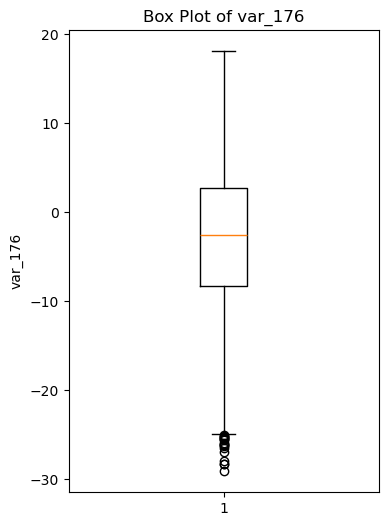

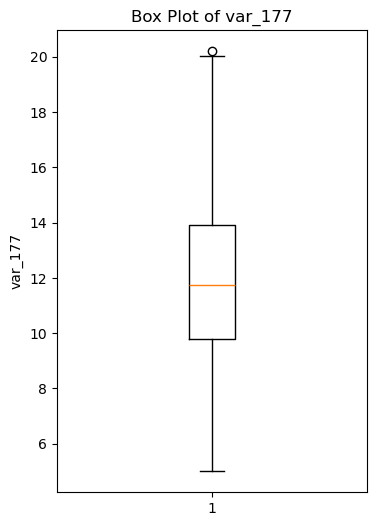

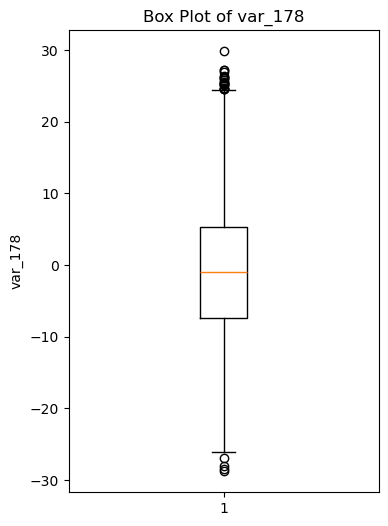

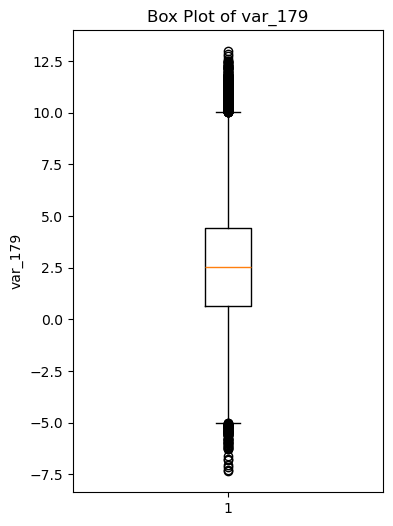

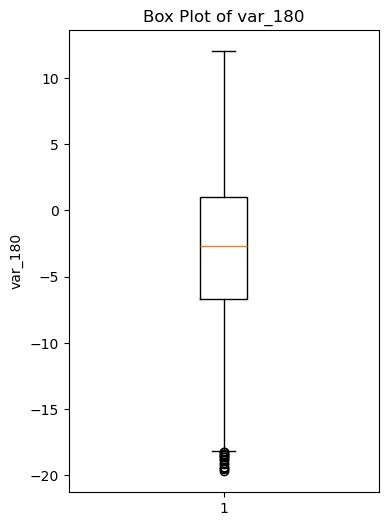

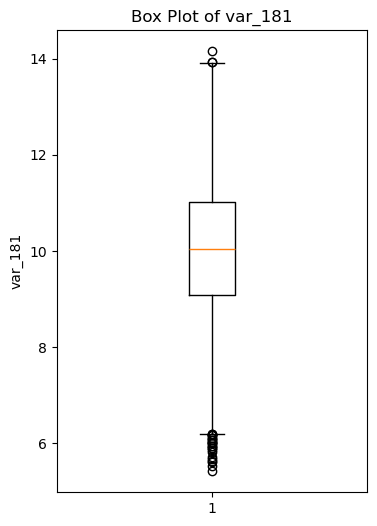

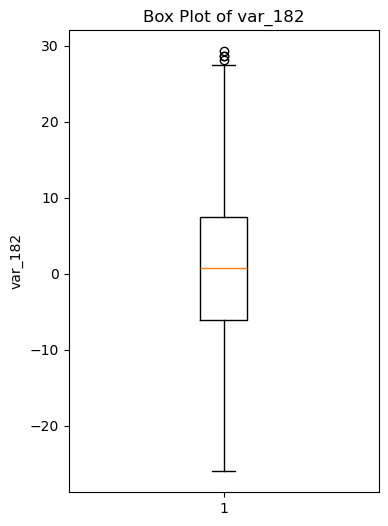

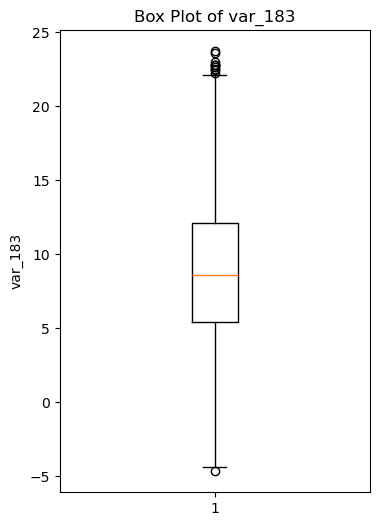

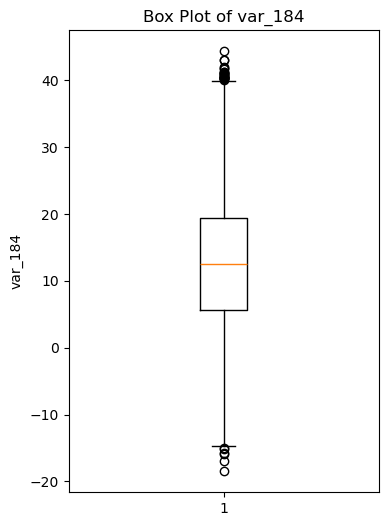

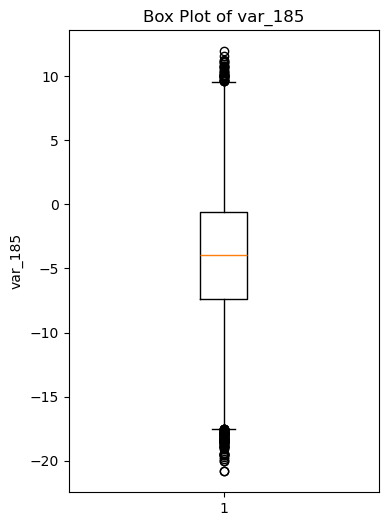

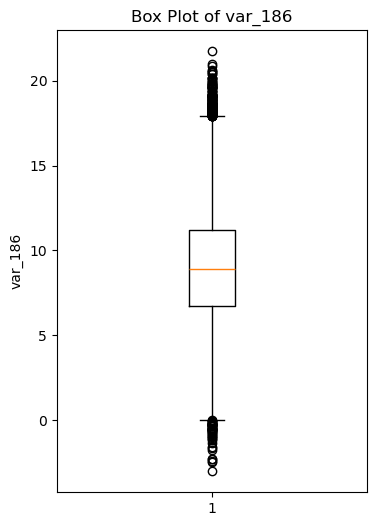

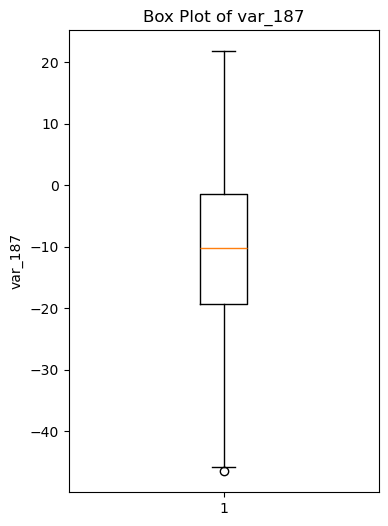

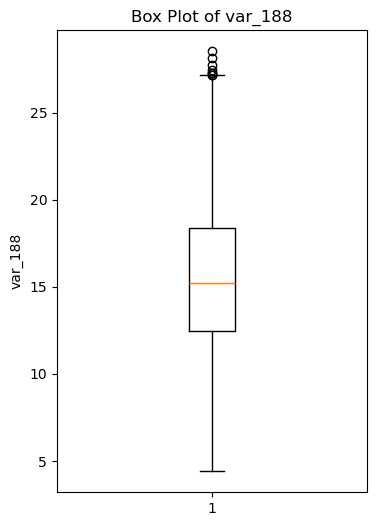

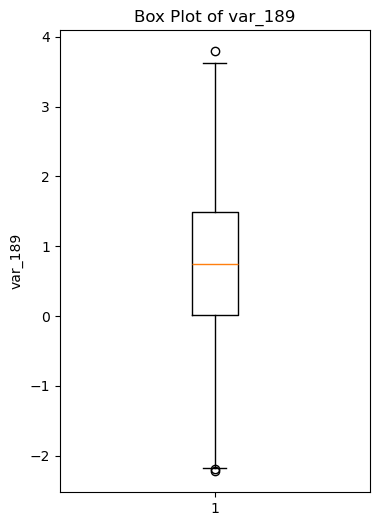

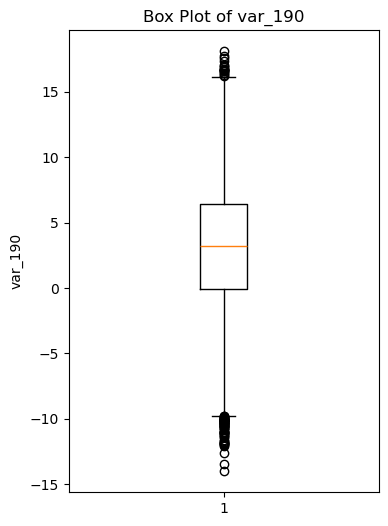

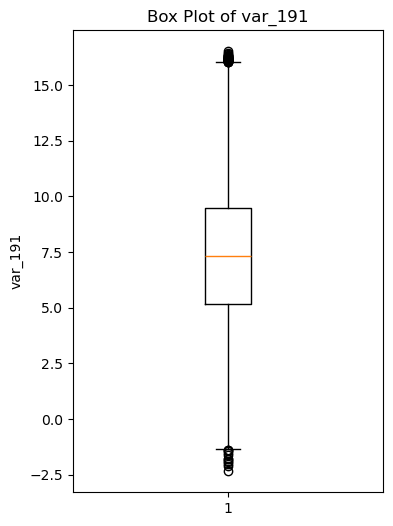

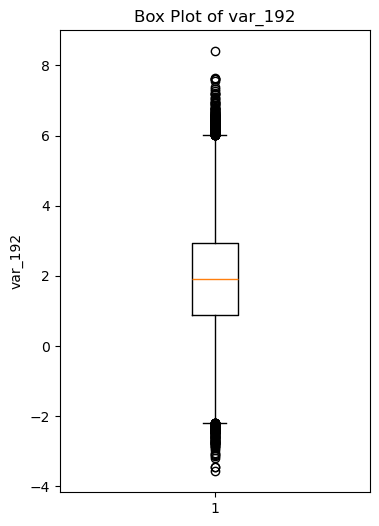

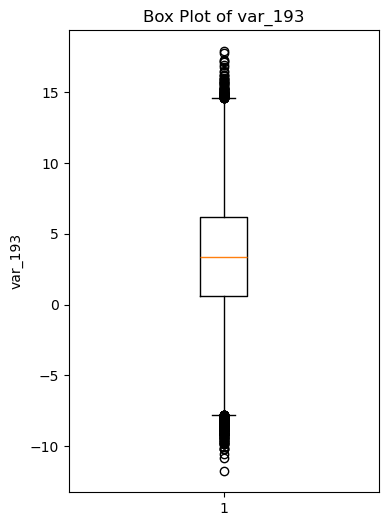

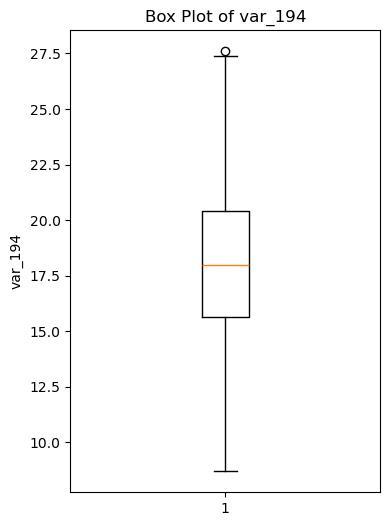

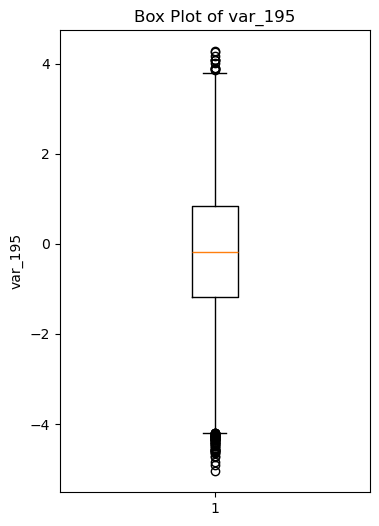

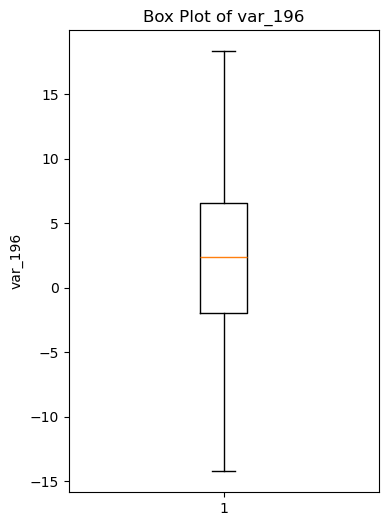

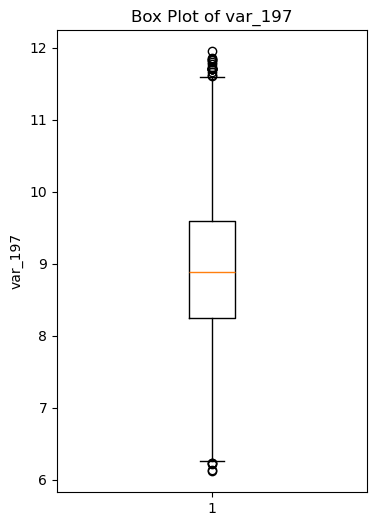

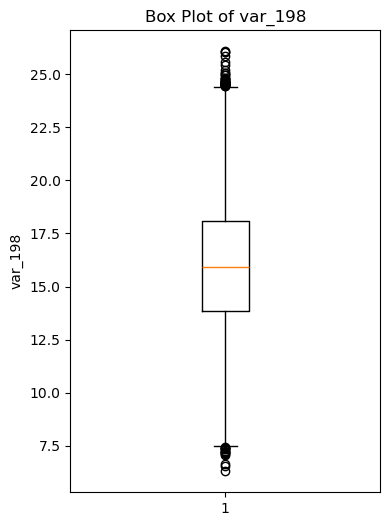

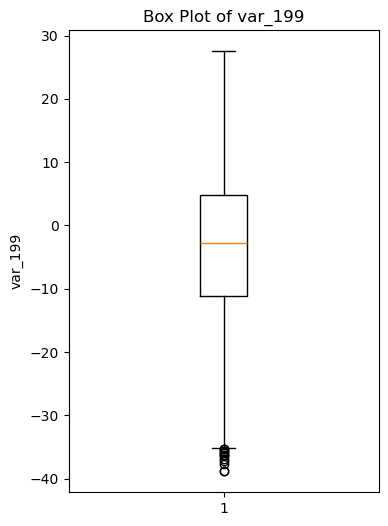

In [24]:
#Excluding id and target, start drawing the boxplot from the third column
cols_to_plot = customer_clean.columns[2:]

print("Variables to plot:", cols_to_plot)

for col in cols_to_plot:
    plt.figure(figsize=(4, 6))
    plt.boxplot(customer_clean[col])
    plt.title(f"Box Plot of {col}")
    plt.ylabel(col)
    plt.show()

In [25]:
# Set random seed
random_seed = 123

# Separate features (X) and target (y)
X = customer_clean.drop(['target', 'ID_code'], axis=1)
y = customer_clean['target']


# Split the dataset into the training set (70%) and test set (30%)
# The training set is the first output, the test set is the second.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state= random_seed,
    stratify= y)

In [26]:
# Find proportion of target classes in the original dataset
print("Original Dataset TARGET Proportions:")
print(customer_clean['target'].value_counts(normalize=True))

# Find proportion of churns in the training set
print("\nTraining Set TARGET Proportions:")
print(y_train.value_counts(normalize=True))


# Find proportion of target classes in the test set
print("\nTest Set TARGET Proportions:")
print(y_test.value_counts(normalize=True))


Original Dataset TARGET Proportions:
target
0    0.89962
1    0.10038
Name: proportion, dtype: float64

Training Set TARGET Proportions:
target
0    0.899614
1    0.100386
Name: proportion, dtype: float64

Test Set TARGET Proportions:
target
0    0.899633
1    0.100367
Name: proportion, dtype: float64


In [27]:
#calculate infomation gain
IG_scores = mutual_info_classif(X_train,y_train,random_state=random_seed)
weights = pd.DataFrame({'attr_importance': IG_scores},index=X_train.columns)
# Sort the weights in decreasing order of information gain values
weights = weights.sort_values('attr_importance', ascending=False)

#make a plot for infomation gain
# Calculate information gain for all features
IG_scores = mutual_info_classif(X_train, y_train, random_state=random_seed)

# Create a DataFrame with the results
weights = pd.DataFrame({'attr_importance': IG_scores}, index=X_train.columns)

# Print weights
print("Information Gain (Mutual Information) Scores:")
print(weights)

Information Gain (Mutual Information) Scores:
         attr_importance
var_0           0.001666
var_1           0.002693
var_2           0.003570
var_3           0.000000
var_4           0.002692
...                  ...
var_195         0.000093
var_196         0.000036
var_197         0.000000
var_198         0.002047
var_199         0.000770

[199 rows x 1 columns]


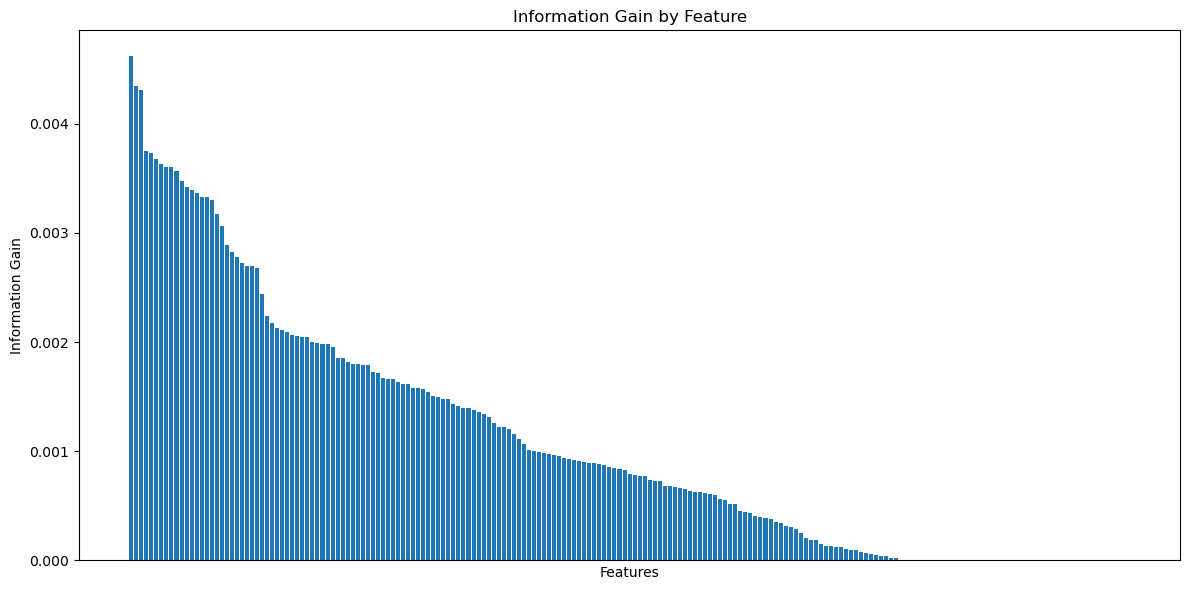

In [28]:
# Plot the weights
weights = weights.sort_values('attr_importance', ascending=False)
plt.figure(figsize=(12, 6))
plt.bar(range(len(weights)), weights['attr_importance'])
plt.xticks(range(len(weights)), weights.index, rotation=90)
plt.xlabel('Features')
plt.ylabel('Information Gain')
plt.title('Information Gain by Feature')
plt.xticks([])
plt.tight_layout()
plt.show()

In [29]:
#Select features with positive importance(attr_importance > 0)
features=weights[weights['attr_importance']>0].index.tolist()
print(len(features))

153


In [30]:
# Subset train and test data to these selected features
X_train_features = X_train[features]
X_test_features = X_test[features]

# Standardize the selected features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_features)
X_test_scaled = scaler.transform(X_test_features)


In [79]:
# Based on small data result to build a logistic regression model(C= 0.01)
Best_LR_c=0.01
LogReg = LogisticRegression(class_weight='balanced',C = Best_LR_c, random_state=random_seed,max_iter=5000)
LogReg.fit(X_train_scaled, y_train)

print("Logistic Regression Model trained successfully")
print(f"\nNumber of Iterations: {LogReg.n_iter_}")
print(f"Training accuracy: {LogReg.score(X_train_scaled, y_train):.4f}")

Logistic Regression Model trained successfully

Number of Iterations: [8]
Training accuracy: 0.7712


In [56]:
# Predict the class probabilities of the test data
LogReg_prob = LogReg.predict_proba(X_test_scaled)[:, 1]   # Get probabilities for class 1   

LogReg_01 = np.where(LogReg_prob >= 0.1, 1, 0)
LogReg_02 = np.where(LogReg_prob >= 0.2, 1, 0)
LogReg_03 = np.where(LogReg_prob >= 0.3, 1, 0)
LogReg_04 = np.where(LogReg_prob >= 0.4, 1, 0)
LogReg_class = np.where(LogReg_prob >= 0.5, 1, 0) 

# Compute and print the confusion matrix
print("Confusion Matrix - Logistic Regression (default threshold = 0.5):")
print(confusion_matrix(y_test, LogReg_class))
print("\nClassification Report - Logistic Regression (default threshold = 0.5):")
print(classification_report(y_test, LogReg_class))

print("\nConfusion Matrix - Logistic Regression (custom threshold = 0.1):")
print(confusion_matrix(y_test, LogReg_01))
print("\nClassification Report - Logistic Regression (custom threshold = 0.1):")
print(classification_report(y_test, LogReg_01))

print("\nConfusion Matrix - Logistic Regression (custom threshold = 0.2):")
print(confusion_matrix(y_test, LogReg_02))
print("\nClassification Report - Logistic Regression (custom threshold = 0.2):")
print(classification_report(y_test, LogReg_02))

print("\nConfusion Matrix - Logistic Regression (custom threshold = 0.3):")
print(confusion_matrix(y_test, LogReg_03))
print("\nClassification Report - Logistic Regression (custom threshold = 0.3):")
print(classification_report(y_test, LogReg_03))

print("\nConfusion Matrix - Logistic Regression (custom threshold = 0.4):")
print(confusion_matrix(y_test, LogReg_04))
print("\nClassification Report - Logistic Regression (custom threshold = 0.4):")
print(classification_report(y_test, LogReg_04))


Confusion Matrix - Logistic Regression (default threshold = 0.5):
[[20773  6216]
 [  745  2266]]

Classification Report - Logistic Regression (default threshold = 0.5):
              precision    recall  f1-score   support

           0       0.97      0.77      0.86     26989
           1       0.27      0.75      0.39      3011

    accuracy                           0.77     30000
   macro avg       0.62      0.76      0.63     30000
weighted avg       0.90      0.77      0.81     30000


Confusion Matrix - Logistic Regression (custom threshold = 0.1):
[[ 5683 21306]
 [   47  2964]]

Classification Report - Logistic Regression (custom threshold = 0.1):
              precision    recall  f1-score   support

           0       0.99      0.21      0.35     26989
           1       0.12      0.98      0.22      3011

    accuracy                           0.29     30000
   macro avg       0.56      0.60      0.28     30000
weighted avg       0.90      0.29      0.33     30000


Confusio

In [57]:
# Choose the best threshold of Logistic Regression
LogReg_final_pred = LogReg_04
LogReg_final_threshold = 0.4

accuracy_logreg = accuracy_score(y_test, LogReg_class)
precision_logreg = precision_score(y_test, LogReg_class)
recall_logreg = recall_score(y_test, LogReg_class)
f1_logreg = f1_score(y_test, LogReg_class)

print(f"\nMetrics for Logistic Regression: (threshold = {LogReg_final_threshold})")
print(f"Accuracy: {accuracy_logreg:.4f}")
print(f"Precision: {precision_logreg:.4f}")
print(f"Recall (Sensitivity): {recall_logreg:.4f}")
print(f"F1-Score: {f1_logreg:.4f}")


Metrics for Logistic Regression: (threshold = 0.4)
Accuracy: 0.7680
Precision: 0.2672
Recall (Sensitivity): 0.7526
F1-Score: 0.3943


In [ ]:
#Based on small data result and build a SVM model with best C

In [33]:
# Build SVM model with probability=True
best_C=0.01
SVM_model = SVC(kernel='rbf', C=best_C, class_weight='balanced',random_state=random_seed, probability=True)
SVM_model.fit(X_train_scaled, y_train)

print("SVM Model trained successfully")
print(f"Training accuracy: {SVM_model.score(X_train_scaled, y_train):.4f}")

SVM Model trained successfully
Training accuracy: 0.7916


In [58]:
SVM_prob = SVM_model.predict_proba(X_test_scaled)[:, 1]
# Predict the class of the test data
SVM_pred_01 = np.where(SVM_prob >= 0.1, 1, 0)
SVM_pred_02 = np.where(SVM_prob >= 0.2, 1, 0)
SVM_pred_03 = np.where(SVM_prob >= 0.3, 1, 0)
SVM_pred_04 = np.where(SVM_prob >= 0.4, 1, 0)
SVM_pred = SVM_model.predict(X_test_scaled)

# Compute confusion matrix
print("Confusion Matrix - SVM (default threshold):")
print(confusion_matrix(y_test, SVM_pred))
print("\nClassification Report - SVM (default threshold):")
print(classification_report(y_test, SVM_pred, zero_division=0))

print("\nConfusion Matrix - SVM (custom threshold = 0.1):")
print(confusion_matrix(y_test, SVM_pred_01))
print("\nClassification Report - SVM (custom threshold = 0.1):")
print(classification_report(y_test, SVM_pred_01, zero_division=0))

print("\nConfusion Matrix - SVM (custom threshold = 0.2):")
print(confusion_matrix(y_test, SVM_pred_02))
print("\nClassification Report - SVM (custom threshold = 0.2):")
print(classification_report(y_test, SVM_pred_02, zero_division=0))

print("\nConfusion Matrix - SVM (custom threshold = 0.3):")
print(confusion_matrix(y_test, SVM_pred_03))
print("\nClassification Report - SVM (custom threshold = 0.3):")
print(classification_report(y_test, SVM_pred_03, zero_division=0))

print("\nConfusion Matrix - SVM (custom threshold = 0.4):")
print(confusion_matrix(y_test, SVM_pred_04))
print("\nClassification Report - SVM (custom threshold = 0.4):")
print(classification_report(y_test, SVM_pred_04, zero_division=0))


Confusion Matrix - SVM (default threshold):
[[21255  5734]
 [  646  2365]]

Classification Report - SVM (default threshold):
              precision    recall  f1-score   support

           0       0.97      0.79      0.87     26989
           1       0.29      0.79      0.43      3011

    accuracy                           0.79     30000
   macro avg       0.63      0.79      0.65     30000
weighted avg       0.90      0.79      0.82     30000


Confusion Matrix - SVM (custom threshold = 0.1):
[[21304  5685]
 [  650  2361]]

Classification Report - SVM (custom threshold = 0.1):
              precision    recall  f1-score   support

           0       0.97      0.79      0.87     26989
           1       0.29      0.78      0.43      3011

    accuracy                           0.79     30000
   macro avg       0.63      0.79      0.65     30000
weighted avg       0.90      0.79      0.83     30000


Confusion Matrix - SVM (custom threshold = 0.2):
[[24306  2683]
 [ 1087  1924]]

Cla

In [77]:
# Choose the best threshold for SVM model
SVM_final_pred = SVM_pred_02
SVM_final_threshold = 0.2

accuracy_svm = accuracy_score(y_test, SVM_final_pred)
precision_svm = precision_score(y_test, SVM_final_pred)
recall_svm = recall_score(y_test, SVM_final_pred)
f1_svm = f1_score(y_test, SVM_final_pred)

print(f"\nMetrics for SVM(threshold = {SVM_final_threshold}):")
print(f"Accuracy: {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall (Sensitivity): {recall_svm:.4f}")
print(f"F1-Score: {f1_svm:.4f}")


Metrics for SVM(threshold = 0.2):
Accuracy: 0.8743
Precision: 0.4176
Recall (Sensitivity): 0.6390
F1-Score: 0.5051


In [35]:
# Build Random Forest model
from sklearn.ensemble import RandomForestClassifier

RF_model = RandomForestClassifier(n_estimators=200,class_weight='balanced', random_state=random_seed)
RF_model.fit(X_train_features, y_train)

print("Random Forest Model trained successfully")
print(f"Training accuracy: {RF_model.score(X_train_features, y_train):.4f}")

Random Forest Model trained successfully
Training accuracy: 1.0000


In [59]:
# Predict the class of the test data
RF_prob = RF_model.predict_proba(X_test_features)[:, 1]

RF_pred_01 = np.where(RF_prob >= 0.1, 1, 0)
RF_pred_02 = np.where(RF_prob >= 0.2, 1, 0)
RF_pred_03 = np.where(RF_prob >= 0.3, 1, 0)
RF_pred_04 = np.where(RF_prob >= 0.4, 1, 0)
RF_pred = RF_model.predict(X_test_features)


# Confusion matrix

print("\nConfusion Matrix - Random Forest (custom threshold = 0.1):")
print(confusion_matrix(y_test, RF_pred_01))
print("\nClassification Report - Random Forest (custom threshold = 0.1):")
print(classification_report(y_test, RF_pred_01, zero_division=0))

print("\nConfusion Matrix - Random Forest (custom threshold = 0.2):")
print(confusion_matrix(y_test, RF_pred_02))
print("\nClassification Report - Random Forest (custom threshold = 0.2):")
print(classification_report(y_test, RF_pred_02, zero_division=0))

print("\nConfusion Matrix - Random Forest (custom threshold = 0.3):")
print(confusion_matrix(y_test, RF_pred_03))
print("\nClassification Report - Random Forest (custom threshold = 0.3):")
print(classification_report(y_test, RF_pred_03, zero_division=0))

print("Confusion Matrix - Random Forest (custom threshold = 0.4):")
print(confusion_matrix(y_test, RF_pred_04))
print("\nClassification Report - Random Forest (custom threshold = 0.4):")
print(classification_report(y_test, RF_pred_04, zero_division=0))

print("Confusion Matrix - Random Forest (default threshold = 0.5):")
print(confusion_matrix(y_test, RF_pred))
print("\nClassification Report - Random Forest (default threshold = 0.5):")
print(classification_report(y_test, RF_pred, zero_division=0))



Confusion Matrix - Random Forest (custom threshold = 0.1):
[[16499 10490]
 [  524  2487]]

Classification Report - Random Forest (custom threshold = 0.1):
              precision    recall  f1-score   support

           0       0.97      0.61      0.75     26989
           1       0.19      0.83      0.31      3011

    accuracy                           0.63     30000
   macro avg       0.58      0.72      0.53     30000
weighted avg       0.89      0.63      0.71     30000


Confusion Matrix - Random Forest (custom threshold = 0.2):
[[26701   288]
 [ 2623   388]]

Classification Report - Random Forest (custom threshold = 0.2):
              precision    recall  f1-score   support

           0       0.91      0.99      0.95     26989
           1       0.57      0.13      0.21      3011

    accuracy                           0.90     30000
   macro avg       0.74      0.56      0.58     30000
weighted avg       0.88      0.90      0.87     30000


Confusion Matrix - Random Forest 

In [60]:
# Choose the best model for RF model
RF_final_pred = RF_pred_01
rf_final_threshold = 0.1

accuracy_rf = accuracy_score(y_test, RF_final_pred)
precision_rf = precision_score(y_test, RF_final_pred)
recall_rf = recall_score(y_test, RF_final_pred)
f1_rf = f1_score(y_test, RF_final_pred)

print(f"\nMetrics for Random Forest (threshold = {rf_final_threshold}):")
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall (Sensitivity): {recall_rf:.4f}")
print(f"F1-Score: {f1_rf:.4f}")


Metrics for Random Forest (threshold = 0.1):
Accuracy: 0.6329
Precision: 0.1916
Recall (Sensitivity): 0.8260
F1-Score: 0.3111


In [37]:
#Build XGBOOST
# Compute the class weight for the positive class
neg, pos = np.bincount(y_train)  
scale_pos_weight = neg / pos
print("scale_pos_weight:", scale_pos_weight)

xgb_model = XGBClassifier(
    # Tree complexity and learning behaviour
    n_estimators=300,       
    max_depth=4,             
    learning_rate=0.1,        
    subsample=0.8,           
    colsample_bytree=0.8,
     # Binary classification setup
    objective='binary:logistic',
    random_state=random_seed,
    eval_metric='logloss',
    # Handle class imbalance by up-weighting the minority
    scale_pos_weight=scale_pos_weight)

# Fit the model on the original (scaled) training data 
xgb_model.fit(X_train_features, y_train)

print("XGBoost Model trained successfully")
print(f"Training accuracy (XGBoost): {xgb_model.score(X_train_features, y_train):.4f}")

scale_pos_weight: 8.96157677529529
XGBoost Model trained successfully
Training accuracy (XGBoost): 0.8962


In [61]:
# Predict probabilities and classes on the SCALED test set
xgb_prob = xgb_model.predict_proba(X_test_features)[:, 1]

xgb_pred = xgb_model.predict(X_test_features)
# Custom thresholds
xgb_pred_01 = np.where(xgb_prob >= 0.1, 1, 0)
xgb_pred_02 = np.where(xgb_prob >= 0.2, 1, 0)
xgb_pred_03 = np.where(xgb_prob >= 0.3, 1, 0)
xgb_pred_04 = np.where(xgb_prob >= 0.4, 1, 0)

print("\nConfusion Matrix - XGBoost (custom threshold = 0.1):")
print(confusion_matrix(y_test, xgb_pred_01))
print("\nClassification Report - XGBoost (custom threshold = 0.1):")
print(classification_report(y_test, xgb_pred_01))

print("\nConfusion Matrix - XGBoost (custom threshold = 0.2):")
print(confusion_matrix(y_test, xgb_pred_02))
print("\nClassification Report - XGBoost (custom threshold = 0.2):")
print(classification_report(y_test, xgb_pred_02))

print("\nConfusion Matrix - XGBoost (custom threshold = 0.3):")
print(confusion_matrix(y_test, xgb_pred_03))
print("\nClassification Report - XGBoost (custom threshold = 0.3):")
print(classification_report(y_test, xgb_pred_03))

print("Confusion Matrix - XGBoost (custom threshold 0.4):")
print(confusion_matrix(y_test, xgb_pred_04))
print("\nClassification Report - XGBoost (custom threshold 0.4):")
print(classification_report(y_test, xgb_pred_04))

print("Confusion Matrix - XGBoost (default threshold 0.5):")
print(confusion_matrix(y_test, xgb_pred))
print("\nClassification Report - XGBoost (default threshold 0.5):")
print(classification_report(y_test, xgb_pred))



Confusion Matrix - XGBoost (custom threshold = 0.1):
[[ 3948 23041]
 [   18  2993]]

Classification Report - XGBoost (custom threshold = 0.1):
              precision    recall  f1-score   support

           0       1.00      0.15      0.26     26989
           1       0.11      0.99      0.21      3011

    accuracy                           0.23     30000
   macro avg       0.56      0.57      0.23     30000
weighted avg       0.91      0.23      0.25     30000


Confusion Matrix - XGBoost (custom threshold = 0.2):
[[11551 15438]
 [  154  2857]]

Classification Report - XGBoost (custom threshold = 0.2):
              precision    recall  f1-score   support

           0       0.99      0.43      0.60     26989
           1       0.16      0.95      0.27      3011

    accuracy                           0.48     30000
   macro avg       0.57      0.69      0.43     30000
weighted avg       0.90      0.48      0.56     30000


Confusion Matrix - XGBoost (custom threshold = 0.3):
[[17

In [62]:
# Choose the best threshold for XGBoost model
xgb_final_pred = xgb_pred
xgb_final_threshold = 0.5

accuracy_xgb  = accuracy_score(y_test, xgb_final_pred)
precision_xgb = precision_score(y_test, xgb_final_pred)
recall_xgb    = recall_score(y_test, xgb_final_pred)
f1_xgb        = f1_score(y_test, xgb_final_pred)

print(f"\nMetrics for XGBoost (threshold = {xgb_final_threshold})::")
print(f"Accuracy : {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall   : {recall_xgb:.4f}")
print(f"F1-Score : {f1_xgb:.4f}")


Metrics for XGBoost (threshold = 0.5)::
Accuracy : 0.8527
Precision: 0.3702
Recall   : 0.6672
F1-Score : 0.4762


In [63]:
# Obtain class probabilities for Logistic Regression 
LR_prob = LogReg.predict_proba(X_test_scaled)[:, 1]

# Obtain class probabilities for Random Forest
RF_prob = RF_model.predict_proba(X_test_features)[:, 1]

# Obtain class probabilities for SVM
SVM_prob = SVM_model.predict_proba(X_test_scaled)[:, 1]

# Obtain class probabilities for XGBoost
xgb_prob = xgb_model.predict_proba(X_test_features)[:, 1]

print("Probability predictions obtained for all models")
print(f"LogReg first 5 probabilities: {LR_prob[:5]}")
print(f"SVM first 5 probabilities: {SVM_prob[:5]}")
print(f"RF first 5 probabilities: {RF_prob[:5]}")
print(f"XGBoost first 5 probabilities: {xgb_prob[:5]}")

Probability predictions obtained for all models
LogReg first 5 probabilities: [0.3188347  0.43672548 0.48157006 0.07723298 0.23988631]
SVM first 5 probabilities: [0.09061899 0.0455343  0.19794314 0.00398211 0.02517342]
RF first 5 probabilities: [0.055 0.14  0.12  0.105 0.08 ]
XGBoost first 5 probabilities: [0.23226358 0.295113   0.44749662 0.22148475 0.2526152 ]


In [64]:
# Logistic Regression
auc_LogReg = roc_auc_score(y_test, LR_prob)

# SVM
auc_SVM = roc_auc_score(y_test, SVM_prob)

# Random Forest
auc_RF = roc_auc_score(y_test, RF_prob)

#XGBoost
auc_xgb = roc_auc_score(y_test, xgb_prob)

print(f"Logistic Regression AUC: {auc_LogReg:.4f}")
print(f"SVM AUC: {auc_SVM:.4f}")
print(f"Random Forest AUC: {auc_RF:.4f}")
print(f"XGBoost AUC: {auc_xgb:.4f}")

Logistic Regression AUC: 0.8443
SVM AUC: 0.8679
Random Forest AUC: 0.7992
XGBoost AUC: 0.8637


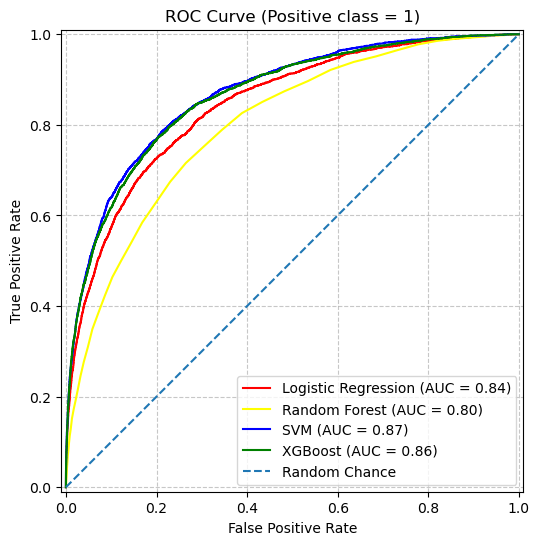

In [65]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 6))

RocCurveDisplay.from_predictions(y_test, LR_prob, name="Logistic Regression", ax=ax, color="red")
RocCurveDisplay.from_predictions(y_test, RF_prob, name="Random Forest", ax=ax, color="yellow")
RocCurveDisplay.from_predictions(y_test, SVM_prob, name="SVM", ax=ax, color="blue")
RocCurveDisplay.from_predictions(y_test, xgb_prob, name="XGBoost", ax=ax, color="green")

ax.plot([0, 1], [0, 1], "--", label="Random Chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve (Positive class = 1)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.7)

plt.show()

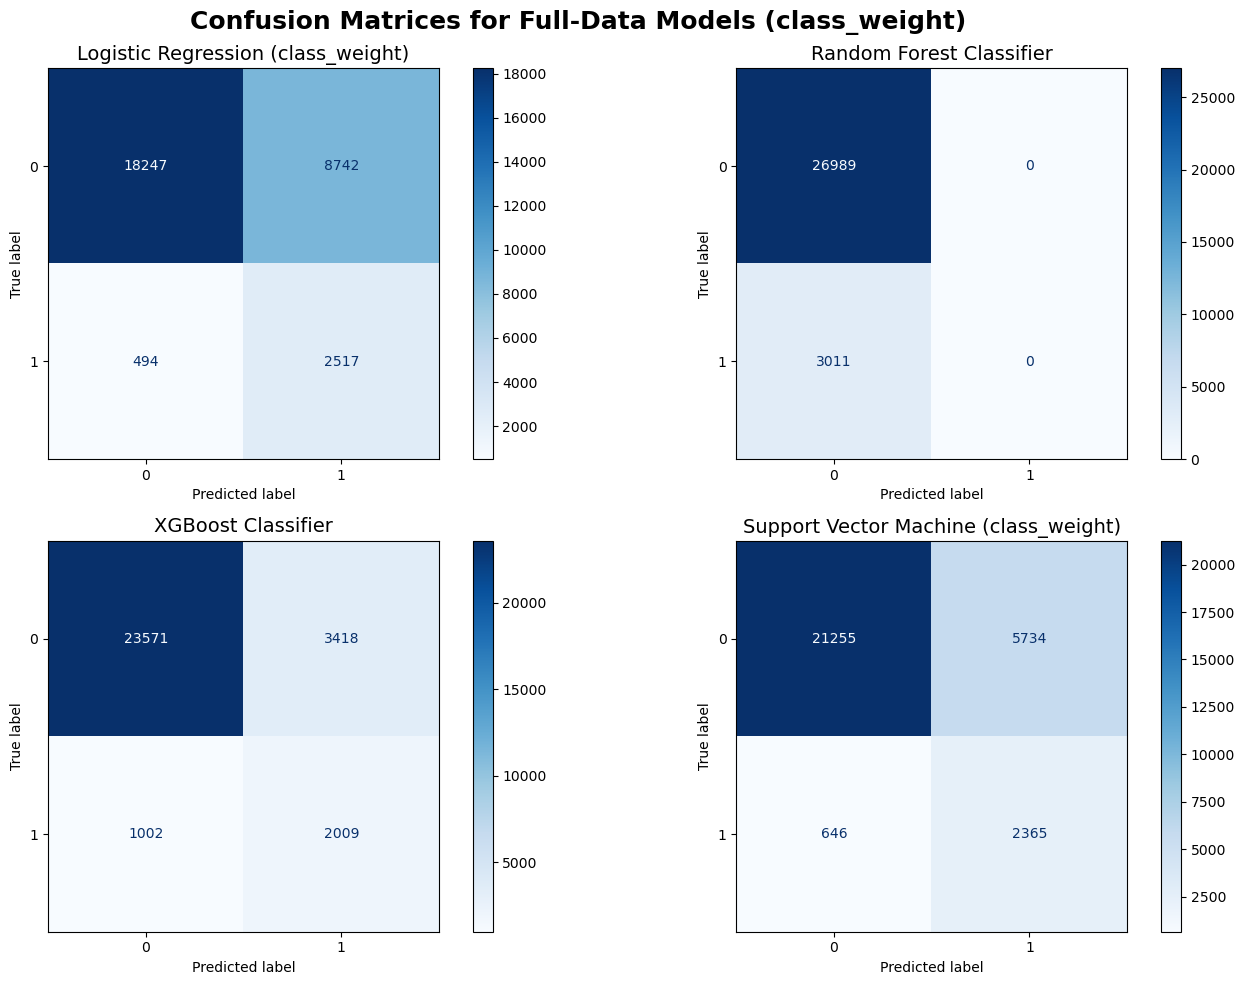

In [82]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Compute confusion matrices
cm_LR  = confusion_matrix(y_test, LogReg_final_pred)       # Logistic Regression
cm_RF  = confusion_matrix(y_test, RF_pred)       # Random Forest
cm_XGB = confusion_matrix(y_test, xgb_pred)      # XGBoost
cm_SVM = confusion_matrix(y_test, SVM_pred)      # SVM (class_weight)

# 2. Create display objects
disp_LR  = ConfusionMatrixDisplay(confusion_matrix=cm_LR,  display_labels=[0, 1])
disp_RF  = ConfusionMatrixDisplay(confusion_matrix=cm_RF,  display_labels=[0, 1])
disp_XGB = ConfusionMatrixDisplay(confusion_matrix=cm_XGB, display_labels=[0, 1])
disp_SVM = ConfusionMatrixDisplay(confusion_matrix=cm_SVM, display_labels=[0, 1])

# 3. Plot in a 2×2 grid
fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(14, 10))
fig.suptitle("Confusion Matrices for Full-Data Models (class_weight)", 
             fontsize=18, fontweight='bold')

disp_LR.plot(ax=axes[0,0], cmap='Blues')
axes[0,0].set_title("Logistic Regression (class_weight)", fontsize=14)

disp_RF.plot(ax=axes[0,1], cmap='Blues')
axes[0,1].set_title("Random Forest Classifier", fontsize=14)

disp_XGB.plot(ax=axes[1,0], cmap='Blues')
axes[1,0].set_title("XGBoost Classifier", fontsize=14)

disp_SVM.plot(ax=axes[1,1], cmap='Blues')
axes[1,1].set_title("Support Vector Machine (class_weight)", fontsize=14)

fig.tight_layout()
plt.show()


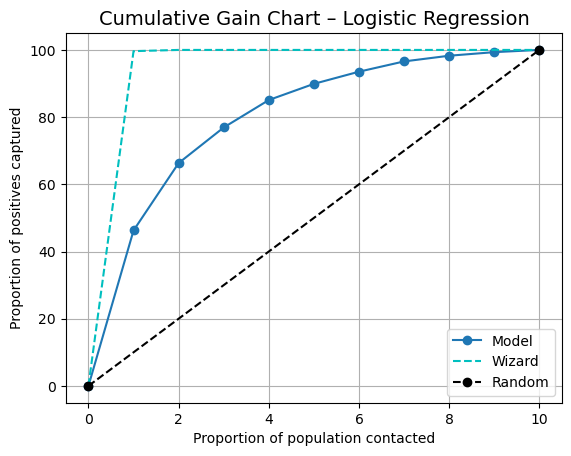

In [66]:
kds.metrics.plot_cumulative_gain(y_test, LR_prob)
plt.title("Cumulative Gain Chart – Logistic Regression", fontsize=14)
plt.xlabel("Proportion of population contacted")
plt.ylabel("Proportion of positives captured")
plt.show()


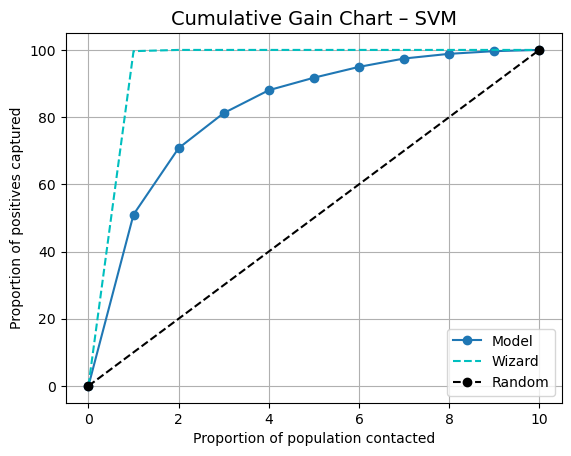

In [67]:
kds.metrics.plot_cumulative_gain(y_test, SVM_prob)
plt.title("Cumulative Gain Chart – SVM", fontsize=14)
plt.xlabel("Proportion of population contacted")
plt.ylabel("Proportion of positives captured")
plt.show()


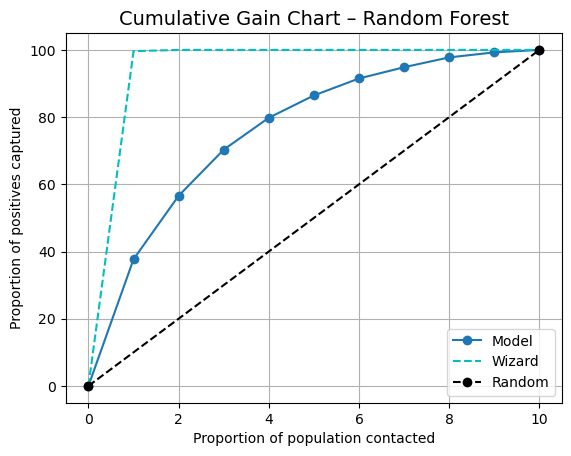

In [68]:
kds.metrics.plot_cumulative_gain(y_test, RF_prob)
plt.title("Cumulative Gain Chart – Random Forest", fontsize=14)
plt.xlabel("Proportion of population contacted")
plt.ylabel("Proportion of positives captured")
plt.show()


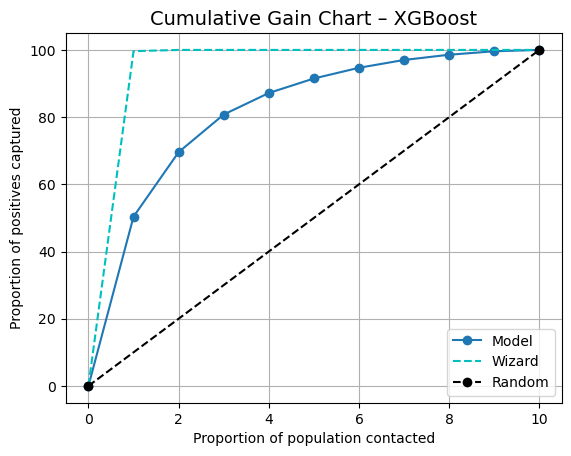

In [69]:
kds.metrics.plot_cumulative_gain(y_test, xgb_prob)
plt.title("Cumulative Gain Chart – XGBoost", fontsize=14)
plt.xlabel("Proportion of population contacted")
plt.ylabel("Proportion of positives captured")
plt.show()


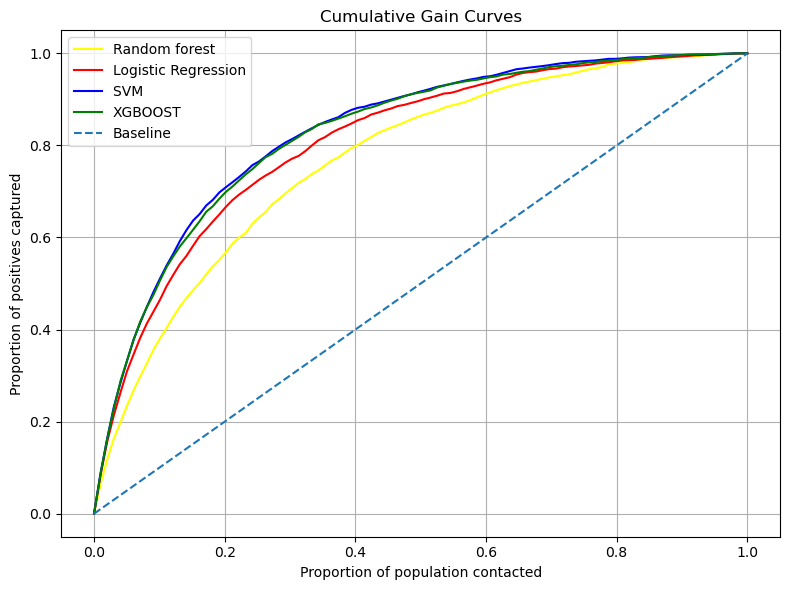

In [70]:
# Define a function to compute the cumulative gain curve
def cumulative_gains(y_true, y_prob, resolution=100):
    # Sort the prediction probs from highest to lowest and store the corresponding indices
    order = np.argsort(y_prob)[::-1]

    # Reorder the true labels (actual target values) so they match the sorted scores
    y_sorted = np.array(y_true)[order]

    # Compute how many positives have been captured
    cum_positives = np.cumsum(y_sorted)

    # Count the total number of positive examples in the dataset
    total_positives = y_sorted.sum()
    
    # Create evenly spaced points between 0 and 1 representing percentages of the population contacted
    perc_population = np.linspace(0, 1, resolution)

    # Convert each population percentage into the corresponding number of individuals
    cutoff = (perc_population * len(y_true)).astype(int)

    # For each cutoff, compute the fraction of all positives has been captured
    gains = cum_positives[np.clip(cutoff - 1, 0, None)] / total_positives
    return perc_population, gains

# curves
x_rf, g_rf  = cumulative_gains(y_test, RF_prob)
x_lr, g_lr  = cumulative_gains(y_test, LR_prob)
x_svm, g_svm = cumulative_gains(y_test, SVM_prob)
x_xgb, g_xgb = cumulative_gains(y_test, xgb_prob)

plt.figure(figsize=(8, 6))
plt.plot(x_rf,  g_rf,  label="Random forest", color="yellow")
plt.plot(x_lr,  g_lr,  label="Logistic Regression", color="red")
plt.plot(x_svm, g_svm, label="SVM ", color="blue")
plt.plot(x_xgb,  g_xgb,  label="XGBOOST", color="green")
plt.plot([0, 1], [0, 1], '--', label="Baseline")

plt.xlabel("Proportion of population contacted")
plt.ylabel("Proportion of positives captured")
plt.title("Cumulative Gain Curves")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

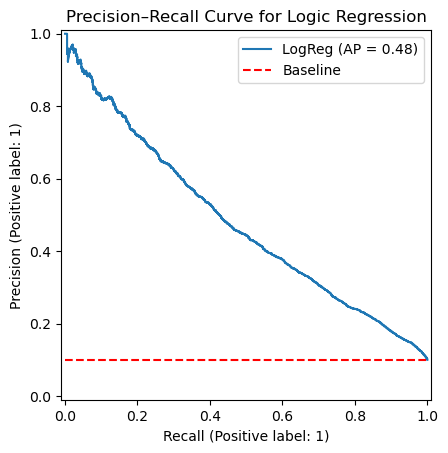

In [71]:
from sklearn.metrics import PrecisionRecallDisplay
#precision–recall curve of Logic regression modeling
fig, ax = plt.subplots()

# create the curve on your own axes
disp = PrecisionRecallDisplay.from_predictions(y_test, LR_prob, name="LogReg", ax=ax)

baseline = y_test.mean()
ax.hlines(baseline, xmin=0, xmax=1, colors='red', linestyles='--', label='Baseline')

ax.set_title("Precision–Recall Curve for Logic Regression")
ax.legend()

plt.show()

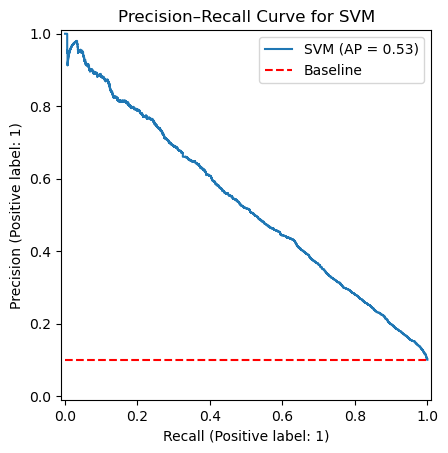

In [72]:
from sklearn.metrics import PrecisionRecallDisplay
#precision–recall curve of SVM modeling
fig, ax = plt.subplots()

# create the curve on your own axes
disp = PrecisionRecallDisplay.from_predictions(y_test, SVM_prob, name="SVM", ax=ax)

baseline = y_test.mean()
ax.hlines(baseline, xmin=0, xmax=1, colors='red', linestyles='--', label='Baseline')

ax.set_title("Precision–Recall Curve for SVM")
ax.legend()

plt.show()

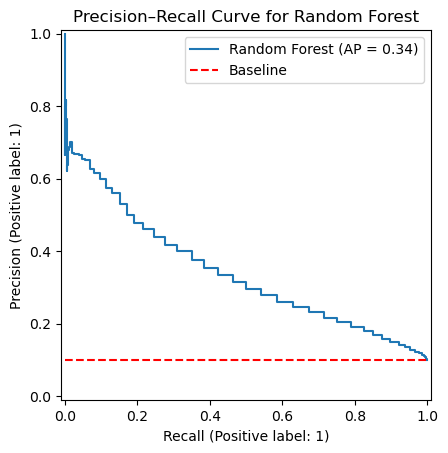

In [73]:
from sklearn.metrics import PrecisionRecallDisplay
#precision–recall curve of Random Forest modeling
fig, ax = plt.subplots()

# create the curve on your own axes
disp = PrecisionRecallDisplay.from_predictions(y_test, RF_prob, name="Random Forest", ax=ax)

baseline = y_test.mean()
ax.hlines(baseline, xmin=0, xmax=1, colors='red', linestyles='--', label='Baseline')

ax.set_title("Precision–Recall Curve for Random Forest")
ax.legend()

plt.show()

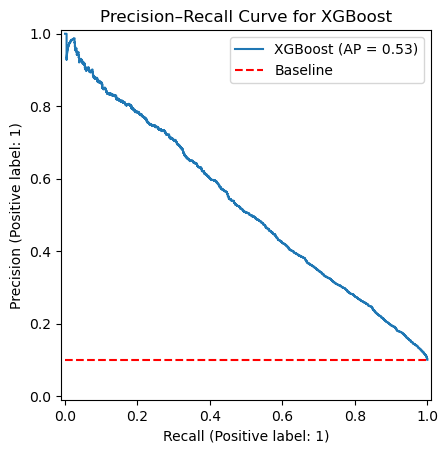

In [74]:
from sklearn.metrics import PrecisionRecallDisplay
#precision–recall curve of XGBoost modeling
fig, ax = plt.subplots()

# create the curve on your own axes
disp = PrecisionRecallDisplay.from_predictions(y_test, xgb_prob, name="XGBoost", ax=ax)

baseline = y_test.mean()
ax.hlines(baseline, xmin=0, xmax=1, colors='red', linestyles='--', label='Baseline')

ax.set_title("Precision–Recall Curve for XGBoost")
ax.legend()

plt.show()

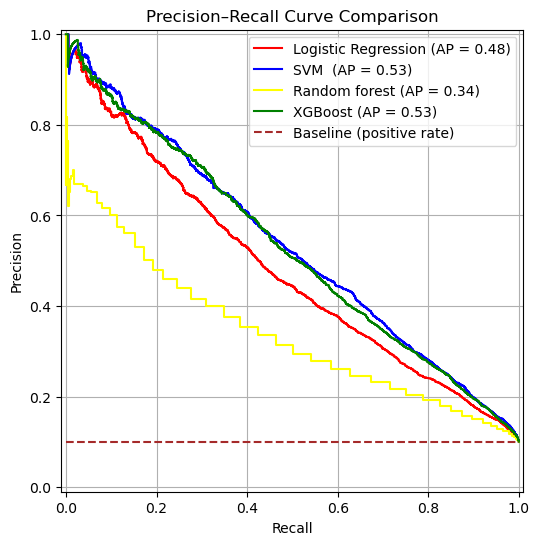

In [75]:
# Precision-Recall
fig, ax = plt.subplots(figsize=(7, 6))
#precision–recall curve of all modeling
PrecisionRecallDisplay.from_predictions(y_test, LR_prob, ax=ax, name="Logistic Regression", color="red")
PrecisionRecallDisplay.from_predictions(y_test, SVM_prob, ax=ax, name="SVM ", color="blue")
PrecisionRecallDisplay.from_predictions(y_test, RF_prob, ax=ax, name="Random forest", color="yellow")
PrecisionRecallDisplay.from_predictions(y_test, xgb_prob, ax=ax, name="XGBoost", color="green")

baseline = y_test.mean()
ax.hlines(baseline, xmin=0, xmax=1,colors="brown", linestyles="--", label="Baseline (positive rate)")

ax.set_title("Precision–Recall Curve Comparison")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
ax.grid(True)
plt.show()

In [78]:
# Create a comprehensive comparison table
comparison_df = pd.DataFrame({
   'Model': ['Logistic Regression', 'SVM', 'Random Forest', 'XGBoost'],
    'Threshold': [0.4, 0.2, 0.1, 0.5],
    'Accuracy':  [accuracy_logreg, accuracy_svm, accuracy_rf, accuracy_xgb],
    'Precision': [precision_logreg, precision_svm, precision_rf, precision_xgb],
    'Recall':    [recall_logreg, recall_svm, recall_rf, recall_xgb],
    'F1-Score':  [f1_logreg, f1_svm, f1_rf, f1_xgb],
    'AUC':       [auc_LogReg, auc_SVM, auc_RF, auc_xgb]
})

print("="*80)
print("CLASS WEIGHT MODEL PERFORMANCE COMPARISON")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)

# Identify the best model for each metric
print("\nBest Models by Metric:")
print(f"Highest Accuracy:  {comparison_df.loc[comparison_df['Accuracy'].idxmax(), 'Model']} ({comparison_df['Accuracy'].max():.4f})")
print(f"Highest Precision: {comparison_df.loc[comparison_df['Precision'].idxmax(), 'Model']} ({comparison_df['Precision'].max():.4f})")
print(f"Highest Recall:    {comparison_df.loc[comparison_df['Recall'].idxmax(), 'Model']} ({comparison_df['Recall'].max():.4f})")
print(f"Highest F1-Score:  {comparison_df.loc[comparison_df['F1-Score'].idxmax(), 'Model']} ({comparison_df['F1-Score'].max():.4f})")
print(f"Highest AUC:       {comparison_df.loc[comparison_df['AUC'].idxmax(), 'Model']} ({comparison_df['AUC'].max():.4f})")
print("="*80)

CLASS WEIGHT MODEL PERFORMANCE COMPARISON
              Model  Threshold  Accuracy  Precision   Recall  F1-Score      AUC
Logistic Regression        0.4  0.767967   0.267154 0.752574  0.394327 0.844349
                SVM        0.2  0.874333   0.417625 0.638990  0.505119 0.867911
      Random Forest        0.1  0.632867   0.191647 0.825971  0.311108 0.799206
            XGBoost        0.5  0.852667   0.370186 0.667220  0.476179 0.863676

Best Models by Metric:
Highest Accuracy:  SVM (0.8743)
Highest Precision: SVM (0.4176)
Highest Recall:    Random Forest (0.8260)
Highest F1-Score:  SVM (0.5051)
Highest AUC:       SVM (0.8679)
